# TP - Regularización, Dropout y Batch Normalization en TNG (20 Newsgroups)
### Redes Neuronales / Deep Learning

En base a la búsqueda de hiperparámetros realizada en el trabajo prácito anterior `TNG+MLP.ipynb`, se prueban las técnicas de regularización por L1 y L2, batch normalization y dropout. 
Se utiliza la estructura de red que se encontró que daba mayor overfitting. 

| Parte | Técnica | Hiperparámetros |
|---|---|---|
| **A** | Regularización **L2**, **L1** y **L1+L2** | `l1`, `l2` (λ) |
| **B** | **Dropout** | `dropout`, `input_dropout`, variación con lr alto + decay + max-norm |
| **C** | **Batch Normalization** | `batchnorm`, `lr`, `batch_size`, `momentum` de BN |

Se mantiene el uso de PyTorch como framework, para poder comparar los resultados a los de los trabajos anteriores. 

## Qué recomiendan los apuntes y dónde lo aplicamos

| Recomendación de clase | Dónde |
|---|---|
| Una única métrica (accuracy de validación) y diagnóstico bias/varianza antes de regularizar | Sección 2 |
| λ en **escala logarítmica**; **no regularizar los biases**; entradas en un mismo rango | Parte A |
| **Histograma de pesos** y observar cómo cambia al subir λ | Parte A |
| L1 como **selector de parámetros**: sacar los pesos ~0 y ver si el resultado cambia | Parte A.4 |
| L2 y confianza del modelo (pesos chicos → probabilidades menos extremas) | Métrica `confianza` |
| Dropout `p` entre 0.2 y 0.5, también en la entrada; red grande | Parte B.1, B.2 |
| Con dropout: **lr más alto con decay, más épocas, max-norm** (4 o 5) | Parte B.3 |
| *"El accuracy en train es mucho más ruidoso que en validación"* | `plot_noise`, métrica de ruido |
| BN: acelera el entrenamiento, regulariza levemente por el ruido del mini-batch; **jugar con el tamaño de batch**; `momentum` del promedio móvil | Parte C |
| BN: activación **después** de BN, `bias` desactivado, **no se suele combinar con dropout** | Modelo y Parte E |
| Biases inicializados en cero | Modelo |

## En cada corrida se miden:
- **Pesos:** `mean|w|`, `max|w|`, % de pesos casi nulos (`|w|<1e-3`) e histograma de `|w|`.
- **Tiempo:** segundos por época (solo la pasada de entrenamiento) y épocas hasta una accuracy objetivo.
- **Learning rate:** barridos con y sin BN, y lr alto con decay en dropout.
- **Ruido** de las curvas: desvío de la accuracy respecto de su media móvil, para train *en modo train* y para validación.
- **Brecha de sobreajuste:** `train_acc - val_acc` con el train evaluado en `eval()`.
- **Confianza:** probabilidad máxima promedio que el modelo asigna en validación. Indica qué tan seguro está el modelo de sus predicciones. Se busca que la confianza sea parecida al accuracy, que querría decir que el modelo trabaja en la zona cercana a la parte lineal de la sigmoidea. 

## 0. Setup

In [9]:
!pip install -q mlflow optuna
!pip install torch
!pip install tensorboard
!pip install nltk

  Using cached nltk-3.10.4-py3-none-any.whl.metadata (5.0 kB)
  Using cached defusedxml-0.7.1-py2.py3-none-any.whl.metadata (32 kB)
Using cached nltk-3.10.4-py3-none-any.whl (1.7 MB)
Using cached defusedxml-0.7.1-py2.py3-none-any.whl (25 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [nltk]2/3 [nltk]


In [ ]:
# Utilidades de Python: expresiones regulares, tiempos, azar y avisos
import re, time, random, warnings
# Datos y gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# PyTorch: tensores, capas, optimizadores, DataLoader y logs de TensorBoard
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torch.utils.tensorboard import SummaryWriter

# scikit-learn: dataset 20 Newsgroups, vectorización TF-IDF, split train/validación y reporte de métricas
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# NLTK: tokenización y stemming (reducir cada palabra a su raíz)
import nltk
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

# mlflow registra parámetros y métricas de cada corrida; optuna busca hiperparámetros
import mlflow
import optuna

# Silencia advertencias y los logs de Optuna para que la salida sea legible
warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Semilla fija para que los resultados sean reproducibles
SEED = 42
def set_seed(seed=SEED):
    # Fija la semilla de Python, NumPy y PyTorch (y la de la GPU, si hay)
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed()

# Usa GPU si está disponible; si no, CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)

Usando dispositivo: cpu


## 1. Datos y features (fijos)

Mejores hiperparámetros de la búsqueda de `TNG+MLP.ipynb`: sin quitar stopwords, stemming, unigramas, `max_features=10000`, `min_df=1`.

In [ ]:
# Descarga el tokenizador de NLTK (lo necesita word_tokenize)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

# Carga 20 Newsgroups sin headers/footers/quotes, para que el modelo aprenda del contenido del mensaje y no de sus metadatos
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))
# Nombres de las 20 categorías y cantidad de clases
class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Train: {len(newsgroups_train.data)} docs | Test: {len(newsgroups_test.data)} docs | Clases: {NUM_CLASSES}")

# Preprocesamiento: minúsculas, solo tokens alfabéticos y stemming (por ejemplo "running" -> "run")
STEMMER = PorterStemmer()

def preprocess_text(text):
    # Tokeniza en minúsculas y descarta números y símbolos (isalpha)
    tokens = [t for t in word_tokenize(text.lower()) if t.isalpha()]
    # Aplica stemming a cada token y los vuelve a unir en un solo texto
    return " ".join(STEMMER.stem(t) for t in tokens)

# Se aplica a todos los textos de train y test
print("Preprocesando (puede tardar un par de minutos)...")
train_proc = [preprocess_text(t) for t in newsgroups_train.data]
test_proc  = [preprocess_text(t) for t in newsgroups_test.data]

Train: 11314 docs | Test: 7532 docs | Clases: 20
Preprocesando (puede tardar un par de minutos)...


In [ ]:
# Convierte textos en vectores TF-IDF
def build_features(fit_texts, other_texts):
    # Solo unigramas y las 10.000 palabras más frecuentes
    vec = TfidfVectorizer(ngram_range=(1, 1), max_features=10000, min_df=1)
    # fit_transform: aprende vocabulario e IDF y transforma
    X_fit = vec.fit_transform(fit_texts)
    # transform: usa el vocabulario ya aprendido, sin reajustarlo
    X_other = vec.transform(other_texts)
    return X_fit, X_other

# Pasa la matriz esparsa a tensores densos de PyTorch (float32 para X, long para las etiquetas)
def to_tensors(X, y):
    return (torch.tensor(X.toarray(), dtype=torch.float32),
            torch.tensor(np.asarray(y), dtype=torch.long))

# Datos para los experimentos: train (80%) / validación (20%) sobre el train original
tr_texts, val_texts, y_tr, y_val = train_test_split(
    train_proc, newsgroups_train.target, test_size=0.2, random_state=SEED,
    stratify=newsgroups_train.target)
# El TF-IDF se ajusta solo con el 80% de entrenamiento
X_tr, X_val = build_features(tr_texts, val_texts)
# Diccionario con los tensores: X_tr/y_tr = entrenamiento, X_ev/y_ev = evaluación (acá, validación)
DATA_EXP = {}
DATA_EXP["X_tr"], DATA_EXP["y_tr"] = to_tensors(X_tr, y_tr)
DATA_EXP["X_ev"], DATA_EXP["y_ev"] = to_tensors(X_val, y_val)
# Cantidad de features de entrada (tamaño del vocabulario)
INPUT_DIM = DATA_EXP["X_tr"].shape[1]
print("Train:", tuple(DATA_EXP["X_tr"].shape), "| Validación:", tuple(DATA_EXP["X_ev"].shape))

Train: (9051, 10000) | Validación: (2263, 10000)


## 2. Modelo

Cada capa oculta es `Linear -> [BatchNorm1d] -> ReLU -> [Dropout]`

- **BN antes de la activación** con **`bias` desactivado** en la capa densa, porque el `β` de BN cumplen esa función.
- **Dropout después de la activación**, con *inverted dropout*: en entrenamiento se escala por `1/keep_prob` y en `eval()` no se elimina nada. 
- **`momentum` de BN en Keras** (`running = m·running + (1-m)·batch`, default 0.99). PyTorch usa la convención inversa, por lo que se utiliza `momentum_torch = 1 - momentum_keras`.
- **L1/L2 como penalidad en la loss**, solo sobre los **pesos** de las capas lineales, con la misma convención que Keras: `λ₂·Σw²` y `λ₁·Σ|w|`.
- **Biases inicializados en cero**.
- **Max-norm** cuando se usa dropout. 

In [ ]:
# MLP configurable de capas ocultas con ReLU y, se varían después BatchNorm y Dropout
class MLP(nn.Module):
    def __init__(self, input_dim, num_classes, hidden_units, dropout=0.0, batchnorm=False):
        super().__init__()
        # "d" lleva la dimensión de salida de la capa anterior
        layers, d = [], input_dim
        for h in hidden_units:
            # Capa lineal; sin bias si hay BatchNorm (el bias queda absorbido por la resta de la media)
            layers.append(nn.Linear(d, h, bias=not batchnorm))
            # BatchNorm antes de la ReLU: normaliza las activaciones de la capa
            if batchnorm:
                layers.append(nn.BatchNorm1d(h))
            # Activación ReLU
            layers.append(nn.ReLU())
            # Dropout después de la activación: apaga neuronas al azar, solo durante el entrenamiento
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            d = h
        # Capa de salida: un logit por clase (la softmax está dentro de CrossEntropyLoss)
        layers.append(nn.Linear(d, num_classes))
        # Encadena todas las capas en un solo módulo
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


# Penalidad de regularización que se suma a la loss: L1 = l1 * suma de |w|, L2 = l2 * suma de w^2
def reg_penalty(model, l1, l2):
    # Penalidad sólo sobre los pesos de las capas Linear (no biases, no BN).
    pen = 0.0
    # Sin regularización no hay nada que sumar
    if l1 == 0 and l2 == 0:
        return pen
    # Recorre las capas y penaliza solo las Linear
    for m in model.modules():
        if isinstance(m, nn.Linear):
            # L1: suma de valores absolutos (empuja los pesos a cero)
            if l1 > 0:
                pen = pen + l1 * m.weight.abs().sum()
            # L2: suma de cuadrados (achica los pesos grandes)
            if l2 > 0:
                pen = pen + l2 * (m.weight ** 2).sum()
    return pen


# Junta |w| de todas las capas Linear en un solo vector (para estadísticas e histogramas)
def linear_weights_abs(model):
    return torch.cat([m.weight.detach().abs().flatten() for m in model.modules() if isinstance(m, nn.Linear)])


# Devuelve el valor absoluto medio, el máximo y la fracción de pesos casi nulos (|w| < thr)
def weight_stats(model, thr=1e-3):
    w = linear_weights_abs(model)
    return w.mean().item(), w.max().item(), (w < thr).float().mean().item()

## 3. Entrenamiento y métricas

`run_experiment` entrena un modelo y guarda por época: loss/accuracy de train (en `eval`), accuracy de train **durante el entrenamiento** (modo train, con máscaras de dropout y estadísticas de batch), loss/accuracy/confianza de validación, estadísticas de pesos, tiempo y learning rate. Loguea en TensorBoard y MLflow.

Métricas que se utilizan para evaluar:
- **Ruido**: desvío de `acc - media_móvil_3(acc)` (desde la época 2), calculado para `val_acc` y para `train_acc` en modo train.
- **Épocas a objetivo**: primera época con `val_acc ≥ TARGET_ACC`.
- **Brecha**: `train_acc(eval) - val_acc` en la última época.
- **Confianza**: probabilidad máxima promedio en validación. 

In [ ]:
EPOCHS = 200
# Configuración base de todos los experimentos; cada corrida sobreescribe solo lo que quiere cambiar
BASE = dict(hidden=[32, 128, 128, 64], optimizer="Adam", lr=1e-3, batch_size=32, epochs=200,
            l1=0.0, l2=0.0, dropout=0.0, batchnorm=False)
# Accuracy objetivo, para contar en cuántas épocas se alcanza
TARGET_ACC = 0.60
# Guarda el resultado (historial, configuración y pesos) de cada corrida, por nombre
RESULTS = {}

# Agrupa todas las corridas en un mismo experimento de MLflow
mlflow.set_experiment("regularizacion_20newsgroups")


# DataLoader reproducible: el generador con semilla fija hace que el orden de los batches sea siempre el mismo
def make_loader(X, y, batch_size, shuffle, seed=SEED):
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=shuffle,
                      generator=g if shuffle else None)


# Evalúa el modelo sobre un loader (sin gradientes): devuelve loss promedio y accuracy
@torch.no_grad()
def evaluate(model, loader):
    # Modo eval: desactiva Dropout y BatchNorm usa sus estadísticas acumuladas
    model.eval()
    # reduction="sum" para promediar bien al final, aunque el último batch sea más chico
    crit = nn.CrossEntropyLoss(reduction="sum")
    loss, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        loss += crit(out, yb).item()
        correct += (out.argmax(1) == yb).sum().item()
        n += xb.size(0)
    return loss / n, correct / n


# Mide el ruido de una curva: desvío estándar de la diferencia entre cada punto y el promedio de sus 3 puntos vecinos
def curve_noise(v):
    v = np.asarray(v, dtype=float)
    if len(v) < 4:
        return float("nan")
    ma = (v[:-2] + v[1:-1] + v[2:]) / 3.0
    return float(np.std(v[1:-1] - ma))


# Crea el optimizador elegido por nombre
def make_optimizer(name, params, lr):
    if name == "Adam":
        return optim.Adam(params, lr=lr)
    if name == "SGD":
        return optim.SGD(params, lr=lr, momentum=0.9)
    if name == "RMSprop":
        return optim.RMSprop(params, lr=lr)
    raise ValueError(name)


# Entrena un modelo con BASE + los cambios (overrides) y lo registra todo: historial por época, TensorBoard y MLflow
def run_experiment(name, group, data=None, trial=None, keep_weights=True, keep_model=False,
                   verbose=True, tb=True, **overrides):
    # Configuración final: BASE con los valores que se pasaron por parámetro
    cfg = {**BASE, **overrides}
    # Por defecto usa train/validación; la parte final usa DATA_FULL (train completo / test)
    data = data or DATA_EXP
    # Misma inicialización en todas las corridas, así las diferencias vienen de la configuración
    set_seed(SEED)

    # Modelo, optimizador y loss
    model = MLP(INPUT_DIM, NUM_CLASSES, cfg["hidden"], cfg["dropout"], cfg["batchnorm"]).to(device)
    opt = make_optimizer(cfg["optimizer"], model.parameters(), cfg["lr"])
    crit = nn.CrossEntropyLoss()
    # Loaders: el de entrenamiento mezcla los datos; los de evaluación no mezclan y usan batch grande
    train_loader = make_loader(data["X_tr"], data["y_tr"], cfg["batch_size"], True)
    train_eval_loader = make_loader(data["X_tr"], data["y_tr"], 1024, False)
    ev_loader = make_loader(data["X_ev"], data["y_ev"], 1024, False)

    # Logs para TensorBoard (opcional)
    writer = SummaryWriter(log_dir=f"runs/reg/{group}/{name}") if tb else None
    # Historial por época de cada métrica
    hist = {k: [] for k in ["train_loss_run", "train_loss", "train_acc", "val_loss", "val_acc",
                            "epoch_time", "mean_abs_w", "max_abs_w", "frac_small_w"]}

    # Cada corrida queda registrada en MLflow
    with mlflow.start_run(run_name=name, nested=True):
        mlflow.log_params({k: str(v) for k, v in cfg.items()})
        mlflow.log_param("group", group)

        # --- Bucle de entrenamiento: una iteración por época ---
        for epoch in range(cfg["epochs"]):
            # Modo train: activa Dropout y BatchNorm usa las estadísticas del batch
            model.train()
            # Con GPU hay que sincronizar antes de medir el tiempo (las operaciones son asíncronas)
            if device.type == "cuda":
                torch.cuda.synchronize()
            # Empieza el cronómetro: se mide solo el pase de entrenamiento
            t0 = time.time()
            # Acumuladores para la loss promedio de la época (medida con Dropout activo)
            run_loss, n = 0.0, 0
            # Recorre los mini-batches del train
            for xb, yb in train_loader:
                xb, yb = xb.to(device), yb.to(device)
                # 1) Limpia los gradientes del paso anterior
                opt.zero_grad()
                # 2) Forward: loss de entropía cruzada (sin la penalidad)
                ce = crit(model(xb), yb)
                # 3) Backward sobre loss + penalidad L1/L2
                (ce + reg_penalty(model, cfg["l1"], cfg["l2"])).backward()
                # 4) Actualiza los pesos
                opt.step()
                # Acumula la loss ponderada por el tamaño del batch
                run_loss += ce.item() * xb.size(0)
                n += xb.size(0)
            # Sincroniza de nuevo antes de frenar el cronómetro
            if device.type == "cuda":
                torch.cuda.synchronize()
            # Segundos que tardó el entrenamiento de esta época
            epoch_time = time.time() - t0

            # Evalúa train y validación en modo eval (sin Dropout) y calcula las estadísticas de los pesos
            tr_loss, tr_acc = evaluate(model, train_eval_loader)
            va_loss, va_acc = evaluate(model, ev_loader)
            mw, xw, fs = weight_stats(model)

            # Guarda las métricas de la época en el historial
            for k, v in zip(hist.keys(), [run_loss / n, tr_loss, tr_acc, va_loss, va_acc, epoch_time, mw, xw, fs]):
                hist[k].append(v)

            # Registra la época en TensorBoard y MLflow
            if writer:
                writer.add_scalars("loss", {"train": tr_loss, "val": va_loss}, epoch)
                writer.add_scalars("accuracy", {"train": tr_acc, "val": va_acc}, epoch)
                writer.add_scalar("weights/mean_abs", mw, epoch)
                writer.add_scalar("time/epoch_s", epoch_time, epoch)
            mlflow.log_metrics({"train_acc": tr_acc, "val_acc": va_acc, "train_loss": tr_loss, "val_loss": va_loss,
                                "mean_abs_w": mw, "epoch_time": epoch_time}, step=epoch)

            # Imprime el avance: primera época, cada 5 y la última
            if verbose and ((epoch + 1) % 5 == 0 or epoch == 0 or epoch + 1 == cfg["epochs"]):
                print(f"[{name}] ep {epoch+1:>2}/{cfg['epochs']} train_acc {tr_acc:.3f} val_acc {va_acc:.3f} "
                      f"val_loss {va_loss:.3f} mean|w| {mw:.5f} t/ep {epoch_time:.1f}s")

            # Si es un trial de Optuna: reporta la accuracy y corta la corrida si el pruner la considera mala
            if trial is not None:
                trial.report(va_acc, epoch)
                if trial.should_prune():
                    if writer: writer.close()
                    raise optuna.TrialPruned()

        # Al terminar guarda |w| para los histogramas (si se pidió)
        w_abs = linear_weights_abs(model).cpu().numpy() if keep_weights else None
        if writer:
            writer.add_histogram("weights/abs", w_abs if w_abs is not None else linear_weights_abs(model).cpu().numpy(),
                                 cfg["epochs"])
            writer.close()

    # Resultado de la corrida
    res = dict(name=name, group=group, cfg=cfg, hist=hist, w_abs=w_abs,
               model=model if keep_model else None,
               total_time=float(np.sum(hist["epoch_time"])))
    # Las corridas de Optuna no se guardan en RESULTS (son muchas)
    if trial is None:
        RESULTS[name] = res
    return res


# Tabla resumen con las métricas finales de cada corrida
def summarize(names):
    rows = []
    for n in names:
        r = RESULTS[n]; h = r["hist"]
        va = np.array(h["val_acc"])
        # Épocas en las que la validación alcanza TARGET_ACC (para ver cuántas hacen falta)
        reached = np.where(va >= TARGET_ACC)[0]
        # Una fila por corrida: mejor y última accuracy, brecha train-val, estadísticas de pesos, tiempo y ruido
        rows.append({
            "run": n,
            "best_val_acc": va.max(),
            "best_epoch": int(va.argmax()) + 1,
            "final_val_acc": va[-1],
            "final_val_loss": h["val_loss"][-1],
            "final_train_acc": h["train_acc"][-1],
            "brecha (train-val)": h["train_acc"][-1] - va[-1],
            "mean|w|": h["mean_abs_w"][-1],
            "max|w|": h["max_abs_w"][-1],
            "% |w|<1e-3": 100 * h["frac_small_w"][-1],
            "s/epoca": float(np.mean(h["epoch_time"])),
            f"epocas a {TARGET_ACC:.0%}": int(reached[0]) + 1 if len(reached) else np.nan,
            "ruido val_acc": curve_noise(va),
        })
    return pd.DataFrame(rows).set_index("run").round(4)


# Grafica en una grilla de 2x3 las curvas de varias corridas (el baseline, en negro y más grueso)
def plot_group(names, title):
    fig, axs = plt.subplots(2, 3, figsize=(17, 8))
    panels = [("val_acc", "Accuracy de validación"), ("val_loss", "Loss de validación"),
              ("train_acc", "Accuracy de train (modo eval)"), ("mean_abs_w", "mean |w| (capas lineales)"),
              ("frac_small_w", "Fracción de pesos con |w| < 1e-3")]
    for ax, (key, ttl) in zip(axs.flat, panels):
        for n in names:
            ax.plot(range(1, len(RESULTS[n]["hist"][key]) + 1), RESULTS[n]["hist"][key], label=n,
                    lw=2.2 if n == "baseline" else 1.4, color="black" if n == "baseline" else None)
        ax.set_title(ttl); ax.set_xlabel("época"); ax.grid(alpha=.3)
    # sexto panel: brecha
    ax = axs.flat[5]
    for n in names:
        h = RESULTS[n]["hist"]
        ax.plot(range(1, len(h["val_acc"]) + 1), np.array(h["train_acc"]) - np.array(h["val_acc"]), label=n,
                lw=2.2 if n == "baseline" else 1.4, color="black" if n == "baseline" else None)
    ax.set_title("Brecha train - val (accuracy)"); ax.set_xlabel("época"); ax.grid(alpha=.3)
    axs.flat[0].legend(fontsize=8)
    fig.suptitle(title, fontsize=14)
    fig.tight_layout()
    plt.show()


# Histograma de |w| en escala log-log por corrida (muestra cuántos pesos quedan cerca de cero)
def plot_weight_hist(names, title):
    fig, ax = plt.subplots(figsize=(9, 4))
    for n in names:
        w = RESULTS[n]["w_abs"]
        ax.hist(w, bins=np.logspace(-8, 0, 80), histtype="step", lw=1.6, label=n)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("|w| (escala log)"); ax.set_ylabel("cantidad de pesos")
    ax.set_title(title); ax.legend(fontsize=8); ax.grid(alpha=.3)
    plt.show()


# Devuelve el nombre de la corrida del grupo con mayor accuracy de validación en la última época
def best_of(group):
    cands = [n for n, r in RESULTS.items() if r["group"] == group]
    return max(cands, key=lambda n: RESULTS[n]["hist"]["val_acc"][-1])

## 4. Línea base

Se parte de la estructura `[32, 128, 128, 64]` que es la que se obtuvo en el trabajo práctico anterior que más sobreajustaba.

In [45]:
run_experiment("baseline", "baseline")
display(summarize(["baseline"]))

h = RESULTS["baseline"]["hist"]
print(f"Train (eval): {h['train_acc'][-1]:.3f} | Validación: {h['val_acc'][-1]:.3f} | brecha: {h['train_acc'][-1]-h['val_acc'][-1]:.3f}")
print(f"Mejor val_acc: {max(h['val_acc']):.3f} en la época {int(np.argmax(h['val_acc']))+1} de {len(h['val_acc'])} "
      f"(referencia de early stopping)")
print(f"Loss de validación: mínima {min(h['val_loss']):.3f} -> final {h['val_loss'][-1]:.3f}")

[baseline] ep  1/200 train_acc 0.383 val_acc 0.331 val_loss 1.973 mean|w| 0.02401 t/ep 0.2s
[baseline] ep  5/200 train_acc 0.858 val_acc 0.463 val_loss 2.619 mean|w| 0.04587 t/ep 0.2s
[baseline] ep 10/200 train_acc 0.944 val_acc 0.487 val_loss 4.963 mean|w| 0.05522 t/ep 0.2s
[baseline] ep 15/200 train_acc 0.956 val_acc 0.504 val_loss 6.188 mean|w| 0.06032 t/ep 0.2s
[baseline] ep 20/200 train_acc 0.966 val_acc 0.495 val_loss 6.747 mean|w| 0.06484 t/ep 0.2s
[baseline] ep 25/200 train_acc 0.970 val_acc 0.507 val_loss 6.729 mean|w| 0.06923 t/ep 0.2s
[baseline] ep 30/200 train_acc 0.947 val_acc 0.498 val_loss 7.395 mean|w| 0.07236 t/ep 0.2s
[baseline] ep 35/200 train_acc 0.972 val_acc 0.512 val_loss 7.488 mean|w| 0.07577 t/ep 0.2s
[baseline] ep 40/200 train_acc 0.960 val_acc 0.513 val_loss 7.111 mean|w| 0.07846 t/ep 0.2s
[baseline] ep 45/200 train_acc 0.973 val_acc 0.510 val_loss 7.267 mean|w| 0.08216 t/ep 0.2s
[baseline] ep 50/200 train_acc 0.971 val_acc 0.510 val_loss 7.676 mean|w| 0.0846

,best_val_acc,best_epoch,final_val_acc,final_val_loss,final_train_acc,brecha,confianza,mean|w|,max|w|,% |w|<1e-3,s/epoca,t total (s),t a mejor ép. (s),t a 60% (s),ruido val,ruido train(modo train)
run,,,,,,,,,,,,,,,,
baseline,0.5594,158,0.5568,8.2773,0.9749,0.4181,0.923,0.1365,2.0494,0.6084,0.2022,40.4381,31.8631,NaN,0.0035,0.0032


Train (eval): 0.975 | Validación: 0.557 | brecha: 0.418
Mejor val_acc: 0.559 en la época 158 de 200 (referencia de early stopping)
Loss de validación: mínima 1.767 -> final 8.277


A lo largo de este trabajo, se va a buscar reducir la brecha entre train y validación, a través de la regularización. 

# Regularización L1 / L2

## Regularización L2 (Ridge)

La penalidad `λ·Σw²` mantiene los pesos bajos, haciendo que las salidas no saturen y se reduzca el overfitting. 

Se aplica **por capa** (podría usarse un λ distinto en cada una) y **no se suelen regularizar los biases**. En el ejemplo de clase, con 500 neuronas, `λ=1e-4` fue un valor razonable y con λ muy grande se observó que aparece *underfitting*.


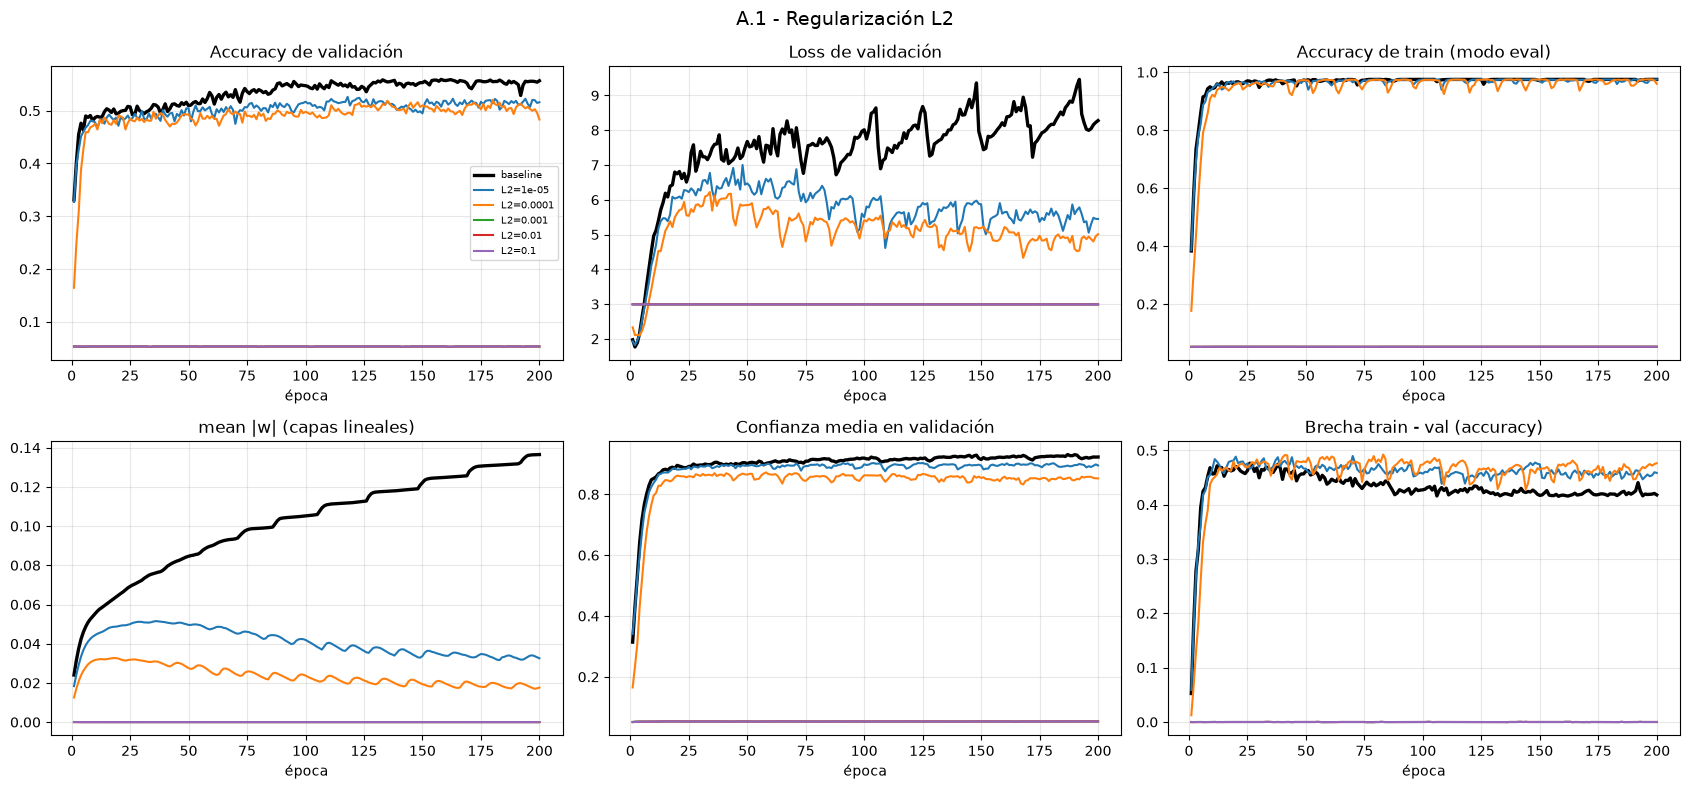

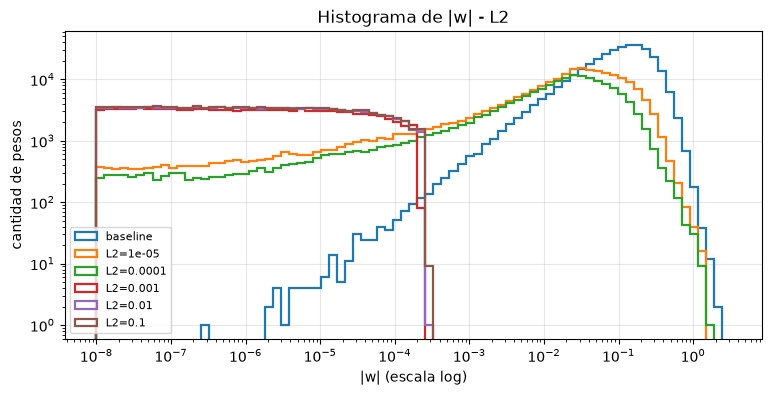

,best_val_acc,best_epoch,final_val_acc,final_val_loss,final_train_acc,brecha,confianza,mean|w|,max|w|,% |w|<1e-3,s/epoca,t total (s),t a mejor ép. (s),t a 60% (s),ruido val,ruido train(modo train)
run,,,,,,,,,,,,,,,,
baseline,0.5594,158,0.5568,8.2773,0.9749,0.4181,0.9230,0.1365,2.0494,0.6084,0.2022,40.4381,31.8631,NaN,0.0035,0.0032
L2=1e-05,0.5263,118,0.5161,5.4482,0.9747,0.4586,0.8952,0.0326,1.4462,44.4867,0.2670,53.3935,31.5070,NaN,0.0045,0.0034
L2=0.0001,0.5205,180,0.4834,5.0094,0.9599,0.4765,0.8526,0.0176,1.6266,59.1887,0.2623,52.4535,47.2324,NaN,0.0042,0.0047
L2=0.001,0.0530,1,0.0530,2.9902,0.0530,0.0000,0.0532,0.0000,0.0002,100.0000,0.2608,52.1693,0.2593,NaN,0.0001,0.0014
L2=0.01,0.0530,1,0.0530,2.9902,0.0530,0.0000,0.0532,0.0000,0.0003,100.0000,0.2645,52.9086,0.2629,NaN,0.0001,0.0013
L2=0.1,0.0530,2,0.0530,2.9902,0.0530,0.0000,0.0532,0.0000,0.0003,100.0000,0.2601,52.0300,0.5138,NaN,0.0001,0.0013


In [46]:
l2_names = []
for l2 in [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]:
    n = f"L2={l2:g}"
    run_experiment(n, "L2", l2=l2, verbose=False)
    l2_names.append(n)
plot_group(["baseline"] + l2_names, "A.1 - Regularización L2")
plot_weight_hist(["baseline"] + l2_names, "Histograma de |w| - L2")
summarize(["baseline"] + l2_names)

**Observaciones**:
- No se ve una reducción de la brecha con ninguno de los valores de λ pero con λ=1e-04 (valor visto como más óptimo en clase) se obtiene la mejor reducción de la loss en validación. Además de una reducción de la confianza. Por lo que se podría decir que aunque 
el accuracy no aumenta, el modelo mejora. 
- Desde λ = 1e-03 en adelante, los accuracy de ambos train y val bajan drásticamente a 0,053 por lo que se comprueba que con λ más altos el modelo presenta underfitting. 
- Al comparar los tiempos hasta la mejor época, se ve que con λ=1-e04 es máximo. Tarda en converger pero es la que da mejores resultados. Para los casos en que λ es mayor, el tiempo a la mejor época se reduce considerablemente mostrando que la convergencia es rápida pero a una solución mala. Para λ más pequeños, se esperaría que el tiempo de convergencia sea mayor pero se obtiene que da menor y más parecido al baseline. Esto se debe a que el modelo sobreajusta rápido y la validación alcanza su máximo antes. Mientras que con el λ óptimo, la validación sigue mejorando más épocas. 

## Regularización L1 (LASSO)

Con L1 *todos* los pesos contribuyen igual al costo y se reducen por igual, haciendo que los pesos chicos lleguen a **cero**. En L2, en cambio, los pesos altos pesan más y se reducen más, pero los chicos casi no se tocan. 

La suma `Σ|w|` crece con la cantidad de pesos por lo que, se elige usar menos pesos para evaluar la técnica. 

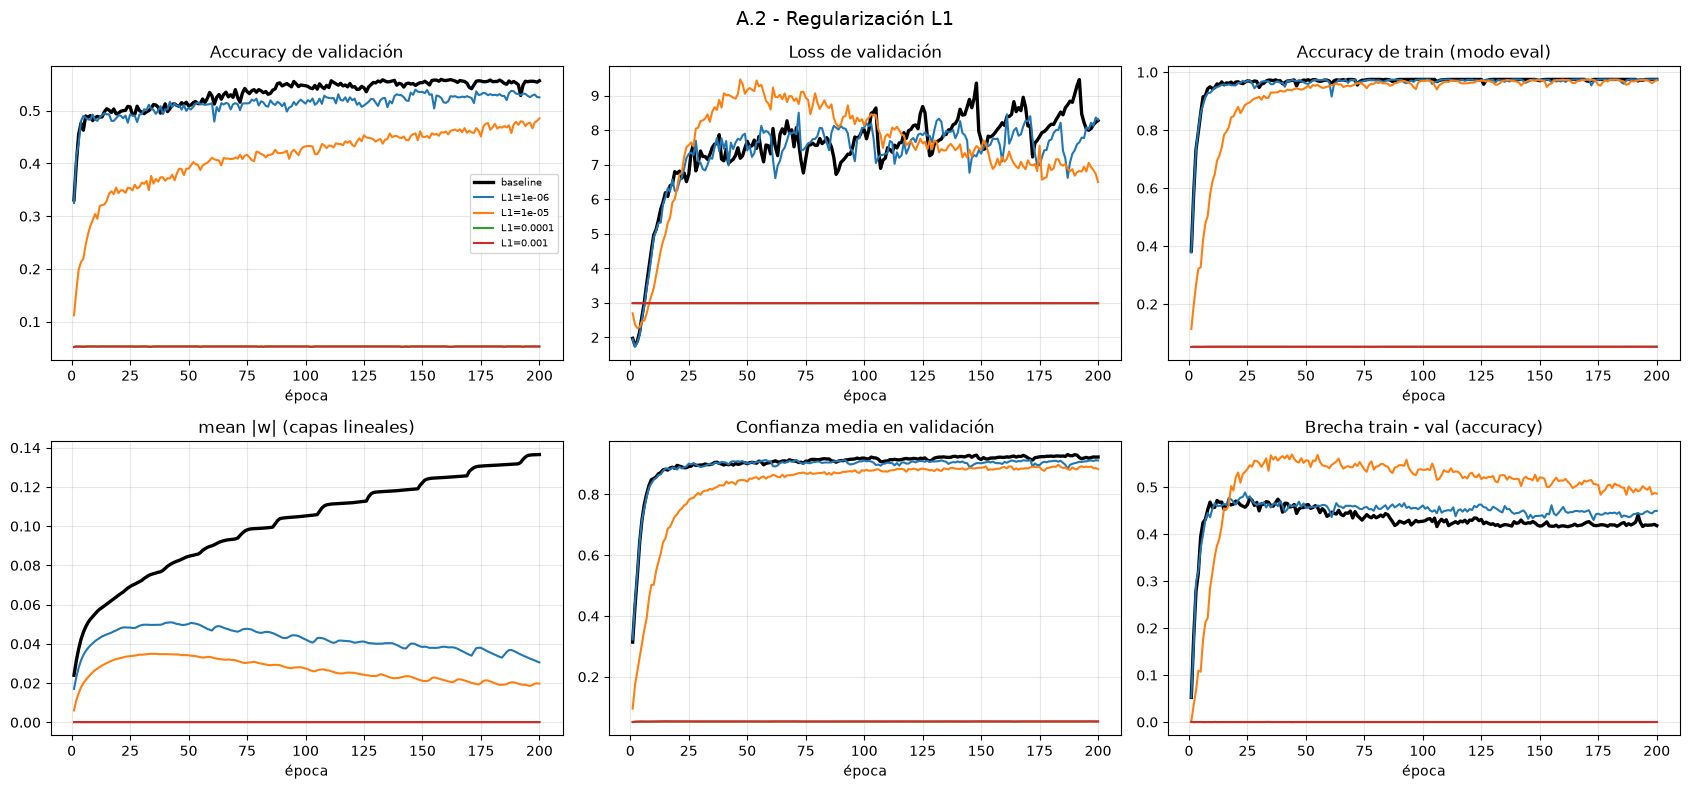

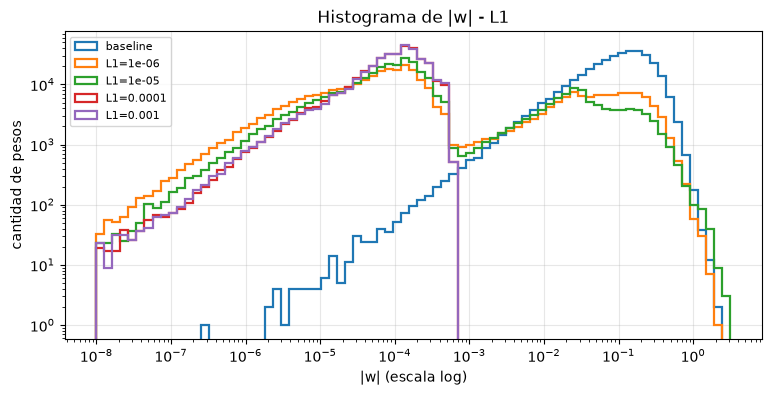

,best_val_acc,best_epoch,final_val_acc,final_val_loss,final_train_acc,brecha,confianza,mean|w|,max|w|,% |w|<1e-3,s/epoca,t total (s),t a mejor ép. (s),t a 60% (s),ruido val,ruido train(modo train)
run,,,,,,,,,,,,,,,,
baseline,0.5594,158,0.5568,8.2773,0.9749,0.4181,0.9230,0.1365,2.0494,0.6084,0.2022,40.4381,31.8631,NaN,0.0035,0.0032
L1=1e-06,0.5400,147,0.5254,8.2976,0.9749,0.4495,0.9116,0.0306,2.4077,68.4680,0.2520,50.4068,37.1514,NaN,0.0049,0.0032
L1=1e-05,0.4856,200,0.4856,6.4964,0.9719,0.4863,0.8833,0.0197,4.5774,73.8721,0.2484,49.6757,49.6757,NaN,0.0041,0.0019
L1=0.0001,0.0530,2,0.0530,2.9902,0.0530,0.0000,0.0532,0.0001,0.0007,100.0000,0.2497,49.9399,0.4935,NaN,0.0001,0.0014
L1=0.001,0.0530,2,0.0530,2.9902,0.0530,0.0000,0.0532,0.0001,0.0007,100.0000,0.2593,51.8557,0.4967,NaN,0.0001,0.0013


In [47]:
l1_names = []
for l1 in [1e-6, 1e-5, 1e-4, 1e-3]:
    n = f"L1={l1:g}"
    run_experiment(n, "L1", l1=l1, verbose=False)
    l1_names.append(n)
plot_group(["baseline"] + l1_names, "A.2 - Regularización L1")
plot_weight_hist(["baseline"] + l1_names, "Histograma de |w| - L1")
summarize(["baseline"] + l1_names)

In [49]:
run_experiment("L1=1e-05|400ep", "L1_largo", l1=1e-5, epochs=400, verbose=False)
summarize(["baseline", "L1=1e-05", "L1=1e-05|400ep"])

,best_val_acc,best_epoch,final_val_acc,final_val_loss,final_train_acc,brecha,confianza,mean|w|,max|w|,% |w|<1e-3,s/epoca,t total (s),t a mejor ép. (s),t a 60% (s),ruido val,ruido train(modo train)
run,,,,,,,,,,,,,,,,
baseline,0.5594,158,0.5568,8.2773,0.9749,0.4181,0.9230,0.1365,2.0494,0.6084,0.2022,40.4381,31.8631,NaN,0.0035,0.0032
L1=1e-05,0.4856,200,0.4856,6.4964,0.9719,0.4863,0.8833,0.0197,4.5774,73.8721,0.2484,49.6757,49.6757,NaN,0.0041,0.0019
L1=1e-05|400ep,0.5011,329,0.4958,6.2579,0.9664,0.4706,0.8916,0.0144,4.9947,80.1364,0.2540,101.6067,84.0418,NaN,0.0036,0.0017


Se realizó una corrida con 400 épocas con λ=1e-05 porque había tenido su mejor época en la 200. El resto tuvo su mejor rendimiento bastante antes de las 200 por lo que se analiza la técnica, combinando las cantidades de épocas.

**Observaciones**:
- Comparado a baseline, no se logró reducir la brecha pero el λ que menos la aumentó fue 1e-06. 
- El λ que más redujo la loss y mejoró la confianza fue el de 1e-05 pero se redujo el accuracy y además es el que necesitó más épocas para establecerse.  
- A partir de λ=1-e03, el modelo colapsó. 
- Con λ=1-e06, ya se obtiene un porcentaje mayor de |w| < 1e-3 que con L2 y mucho mayor que baseline. Comparando el histogramas de pesos de L2 con este, se observa que los obtenidos con λ mayores se corren más hacia el 0 que en L2. Esto muestra que, efectivamente, los pesos más chicos terminan estando más cerca del 0 con L1 que con L2.
Para los λ más chicos, los histogramas son parecidos tanto para L1 como para L2. Entonces, se podría decir que desde ese punto de vista, se obtienen resultados similares si se toman λ chicos. 
- En cuanto a los tiempos de convergencia, se obtiene que aumentan a medida que aumenta λ sin depender de su valor. A diferencia de lo que pasa en L2, que los tiempos totales se mantienen constantes. Esto se corresponde con cómo funciona L1 porque el gradiente tiene magnitud constante. Entonces, hace que los pesos que valen casi cero sigan oscilando alrededor de este valor y cuanto mayor sea λ, mayor la oscilación y más tiempo tarda. 
- Por otro lado, se ve en los pesos que con el aumento de λ, estos se acercan más a 0 pero su valor máximo aumenta. 
- Comparando los resultados (acc val= 0,5254, acc train= 0,9749 con λ=1-e06) con los de L2 (acc val= 0,4834, acc train= 0.9599), se podría decir que se obtiene un poco menos de overfitting pero no hay una mejora considerable. 
L1 funciona un poco mejor para nuestro dataset porque estaría eliminando directamente las palabras poco informativas. Mientras que L2, achica sus pesos pero no los hace valer 0. 

## L1 + L2


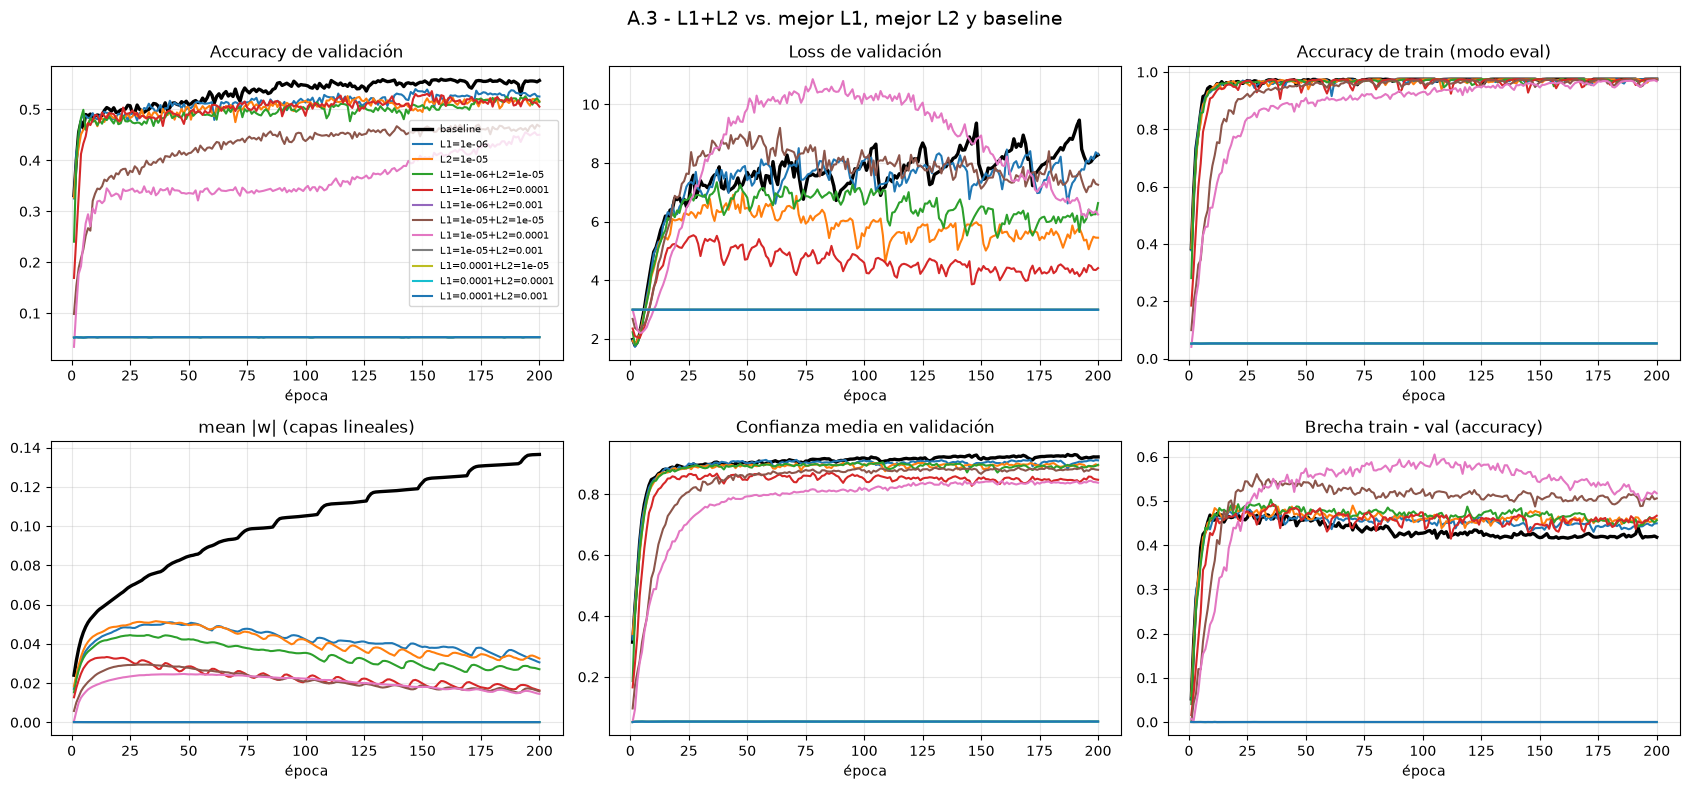

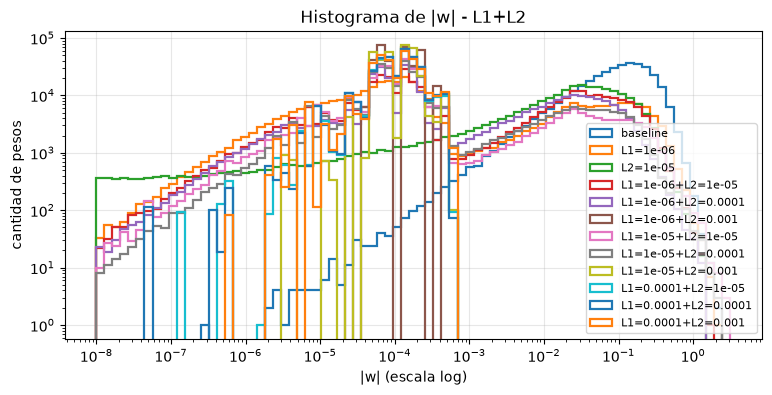

,best_val_acc,best_epoch,final_val_acc,final_val_loss,final_train_acc,brecha,confianza,mean|w|,max|w|,% |w|<1e-3,s/epoca,t total (s),t a mejor ép. (s),t a 60% (s),ruido val,ruido train(modo train)
run,,,,,,,,,,,,,,,,
baseline,0.5594,158,0.5568,8.2773,0.9749,0.4181,0.9230,0.1365,2.0494,0.6084,0.2022,40.4381,31.8631,NaN,0.0035,0.0032
L1=1e-06,0.5400,147,0.5254,8.2976,0.9749,0.4495,0.9116,0.0306,2.4077,68.4680,0.2520,50.4068,37.1514,NaN,0.0049,0.0032
L2=1e-05,0.5263,118,0.5161,5.4482,0.9747,0.4586,0.8952,0.0326,1.4462,44.4867,0.2670,53.3935,31.5070,NaN,0.0045,0.0034
L1=1e-06+L2=1e-05,0.5259,194,0.5148,6.6306,0.9711,0.4562,0.8969,0.0271,1.5904,60.2468,0.3357,67.1415,65.2559,NaN,0.0052,0.0032
L1=1e-06+L2=0.0001,0.5360,154,0.5055,4.4116,0.9723,0.4667,0.8478,0.0163,1.4133,63.4150,0.3208,64.1658,48.6987,NaN,0.0048,0.0048
L1=1e-06+L2=0.001,0.0530,2,0.0530,2.9902,0.0530,0.0000,0.0532,0.0001,0.0003,100.0000,0.3356,67.1277,0.6385,NaN,0.0001,0.0014
L1=1e-05+L2=1e-05,0.4702,174,0.4671,7.2541,0.9732,0.5061,0.8804,0.0158,2.8133,79.8375,0.3437,68.7473,60.6613,NaN,0.0040,0.0020
L1=1e-05+L2=0.0001,0.4551,194,0.4503,6.2393,0.9677,0.5175,0.8381,0.0145,3.5513,75.4821,0.3150,62.9942,61.0080,NaN,0.0044,0.0022
L1=1e-05+L2=0.001,0.0530,2,0.0530,2.9902,0.0530,0.0000,0.0532,0.0001,0.0007,100.0000,0.3423,68.4615,1.1202,NaN,0.0001,0.0014


In [51]:
l12_names = []
for l1 in [1e-6, 1e-5, 1e-4]:
    for l2 in [1e-5, 1e-4, 1e-3]:
        n = f"L1={l1:g}+L2={l2:g}"
        run_experiment(n, "L1+L2", l1=l1, l2=l2, verbose=False)
        l12_names.append(n)

ref = ["baseline", best_in(["L1"]), best_in(["L2"])]
plot_group(ref + l12_names, "A.3 - L1+L2 vs. mejor L1, mejor L2 y baseline")
plot_weight_hist(ref + l12_names, "Histograma de |w| - L1+L2")
summarize(ref + l12_names)

**Observaciones**:
- La mejor combinación se obtiene con L1=1e-6 y L2=1e-4 con 0.5360. Queda entre la mejor L2 (0.5263) y la mejor L1 (0.5400), y por debajo del baseline (0.5594). Aún así, con L1 la diferencia es mínima y seguramente varíe al cambiar la semilla. Por lo que, se puede decir que en este caso combinar L1 y L2 no mejora el accuracy. 
Con la combinación mencionada, se obtiene la menor loss de validación y la menor confianza. 
- La combinación no reduce más el overfitting que usar L2 o L1 de forma separada. 
- La mejora se ve en la reducción del valor de los pesos, max|w| baja de 2.41 (L1=1e-6 sola) a 1.41–1.59 con L2, y de 4.58 (L1=1e-5 sola) a 3.55. Se mantiene la esparsidad (60–80% de pesos por debajo de 1e-3) con valores máximos más contenidos.
- Se duplica el tiempo hasta la mejor época al combinarse las 2. Desde el punto de vista de tiempos, no hay mejoras. 

# Dropout


Se "apagan" aleatoriamente neuronas durante el entrenamiento haciendo que la red no se entrena completa en cada paso. `dropout_rate = 1 - keep_prob`; en entrenamiento se divide por `keep_prob` para mantener la media; **en evalución no se elimina conexiones**. 

Tips: **valores entre 20% y 50%** y usar una **red grande**. Observaciones del ejemplo de clase: hubo que **subir el learning rate**, **aumentar las épocas** (de 2000 a 4000) y *"el accuracy en train es mucho más ruidoso que en validación"*.

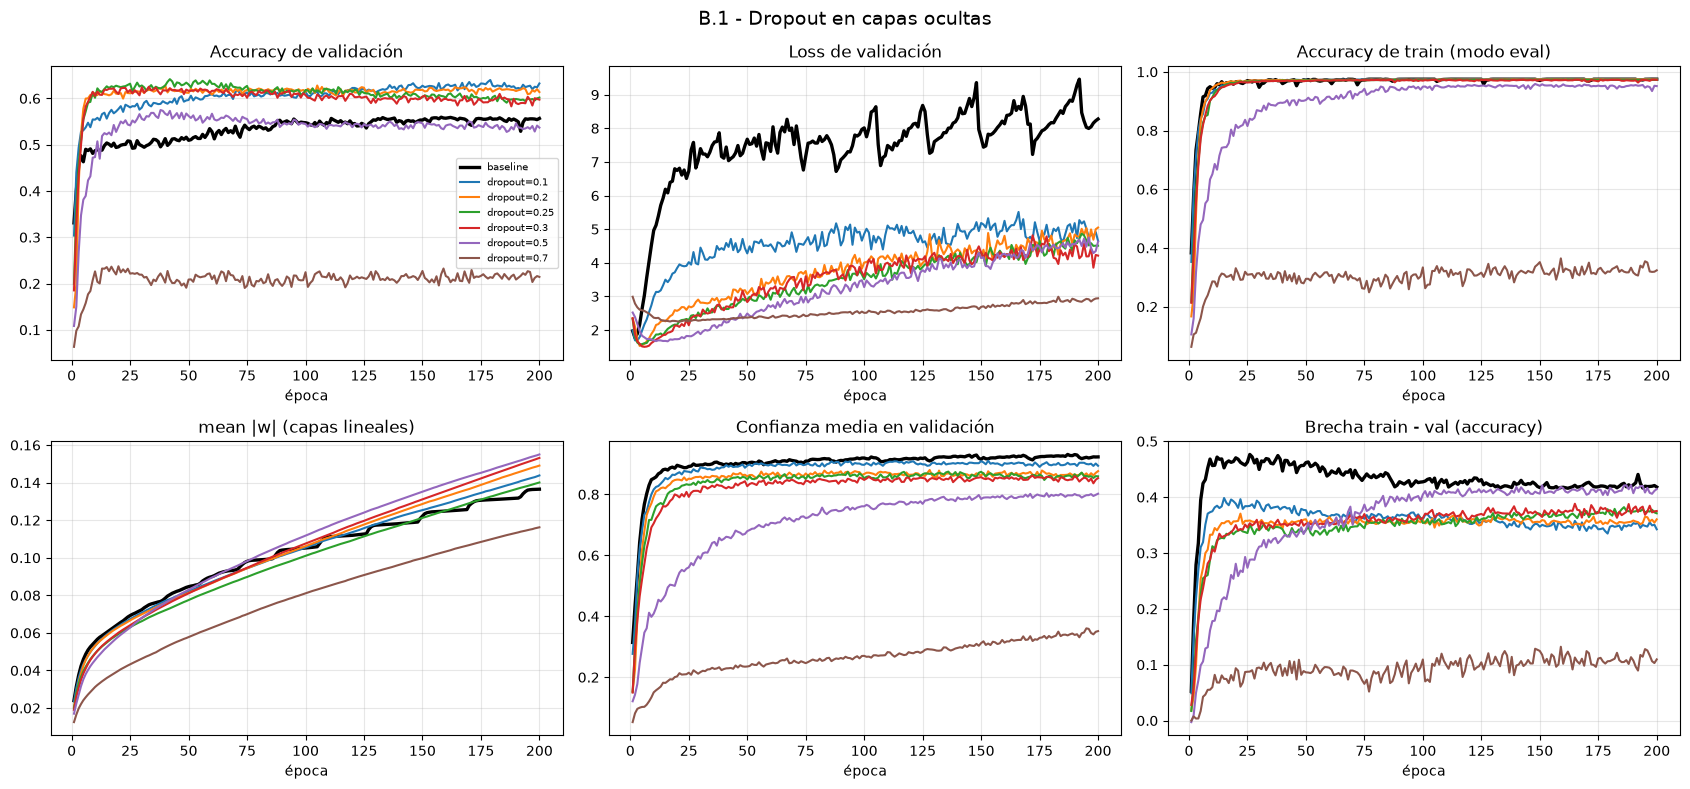

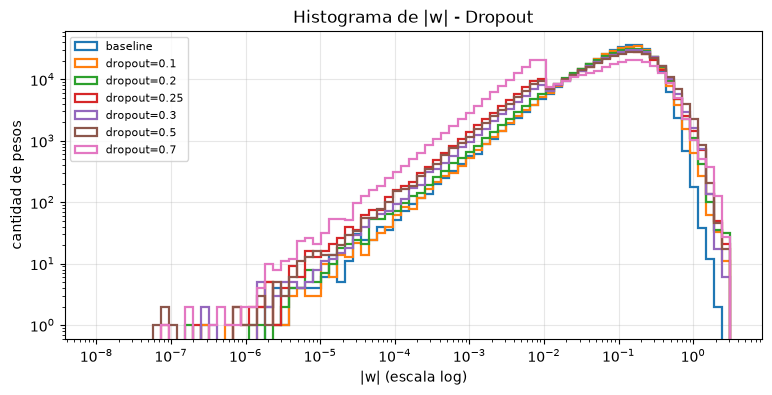

,best_val_acc,best_epoch,final_val_acc,final_val_loss,final_train_acc,brecha,confianza,mean|w|,max|w|,% |w|<1e-3,s/epoca,t total (s),t a mejor ép. (s),t a 60% (s),ruido val,ruido train(modo train)
run,,,,,,,,,,,,,,,,
baseline,0.5594,158,0.5568,8.2773,0.9749,0.4181,0.9230,0.1365,2.0494,0.6084,0.2022,40.4381,31.8631,NaN,0.0035,0.0032
dropout=0.1,0.6399,179,0.6323,4.6514,0.9748,0.3425,0.8939,0.1438,3.0056,0.6001,0.2403,48.0574,43.1238,10.0713,0.0040,0.0023
dropout=0.2,0.6279,40,0.6138,5.0484,0.9740,0.3602,0.8763,0.1491,4.6931,0.7847,0.2320,46.3916,9.2686,1.6151,0.0057,0.0028
dropout=0.25,0.6416,42,0.6019,4.5092,0.9729,0.3711,0.8592,0.1401,4.7362,1.5345,0.2303,46.0590,9.5970,2.0029,0.0040,0.0025
dropout=0.3,0.6253,33,0.5974,4.2134,0.9726,0.3752,0.8535,0.1532,2.9773,1.0830,0.2294,45.8711,7.7383,1.7976,0.0039,0.0024
dropout=0.5,0.5749,38,0.5369,4.6314,0.9514,0.4145,0.8022,0.1550,4.4241,1.3699,0.2312,46.2441,8.9539,NaN,0.0055,0.0032
dropout=0.7,0.2373,20,0.2143,2.9430,0.3238,0.1095,0.3514,0.1162,3.5126,3.2802,0.2339,46.7811,4.7867,NaN,0.0059,0.0033


In [57]:
do_names = []
for p in [0.1, 0.2, 0.25, 0.3, 0.5, 0.7]:
    n = f"dropout={p:g}"
    run_experiment(n, "Dropout", dropout=p, verbose=False)
    do_names.append(n)
plot_group(["baseline"] + do_names, "B.1 - Dropout en capas ocultas")
plot_weight_hist(["baseline"] + do_names, "Histograma de |w| - Dropout")
summarize(["baseline"] + do_names)

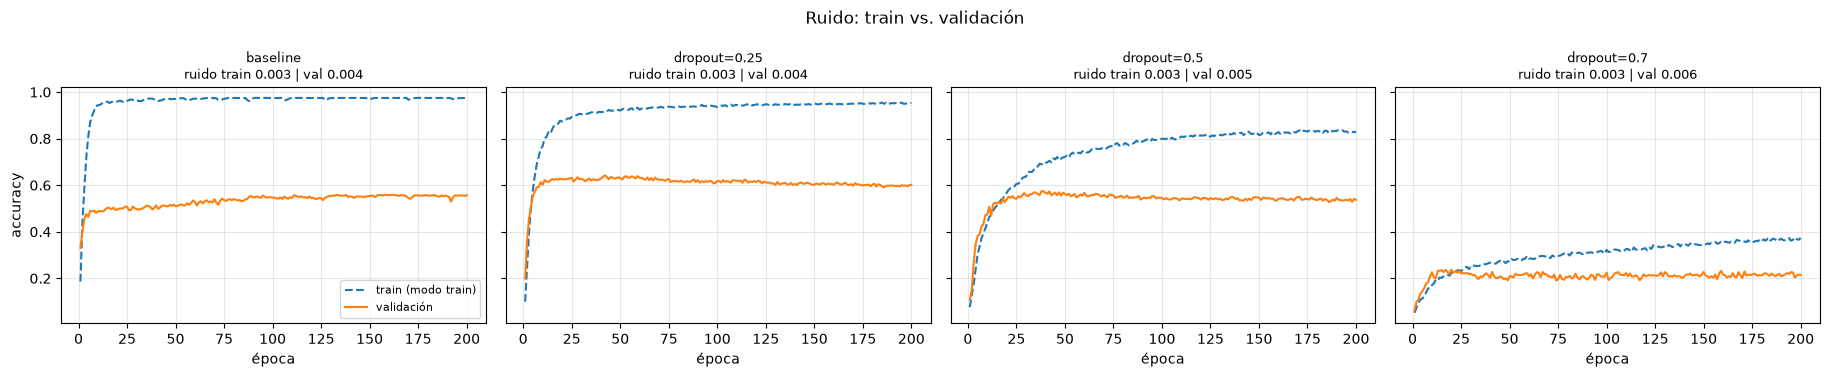

In [58]:
plot_noise(["baseline", "dropout=0.25", "dropout=0.5", "dropout=0.7"], "Ruido: train vs. validación")

**Observaciones** :
- El rango óptimo de dropout se ubica entre 0.1 y 0.3 (accuracy de validación de 0.625 a 0.642), y las diferencias dentro de ese rango no son muy grandes por lo que no se puede concluir con una sola semilla. 
- p=0.25 obtuvo la mayor accuracy y una de las menores loss de validación (coincide con el valor de referencia de la clase). 
- Viendo el histograma de pesos, se observa que la distribución casi que no cambia con respecto a baseline a diferencia de las regularizaciones L2 y L1. Esto tiene sentido porque droput es un método que regulariza por ruido y no por la norma de los pesos. 
- Se esperaba que con dropout, se necesite más tiempo de convergencia que con baseline pero se obtuvo lo contrario. Salvo para el caso de p=0,1 que sí tardó más que baseline. 
- Con p=0.7 el modelo hace underfitting y con p=0.5 la accuracy en train ya empieza a decrecer. 
- Al graficar el ruido en train con el de validación, se observa que el train es más ruidoso que la validación como se vio en clase. Por otro lado, en baseline la validación va subiendo a medida que pasan las aumentan las épocas. Mientras que con dropout, se llega a un valor máximo al principio y luego empieza a decaer abriéndose la brecha (salvo en p=0.7 que no lo consideramos porque sabemos que hace underfitting). 
- Los pesos se mantienen parecidos a los de baseline, coincidiendo con lo ya explicado de la forma de regularización de dropout. 

## Dropout en la entrada

En esta parte se prueba usarlo tanto en la capa visible como en las capas ocultas. 
Se parte en la entrada con 10.000 pesos TF-IDF. 

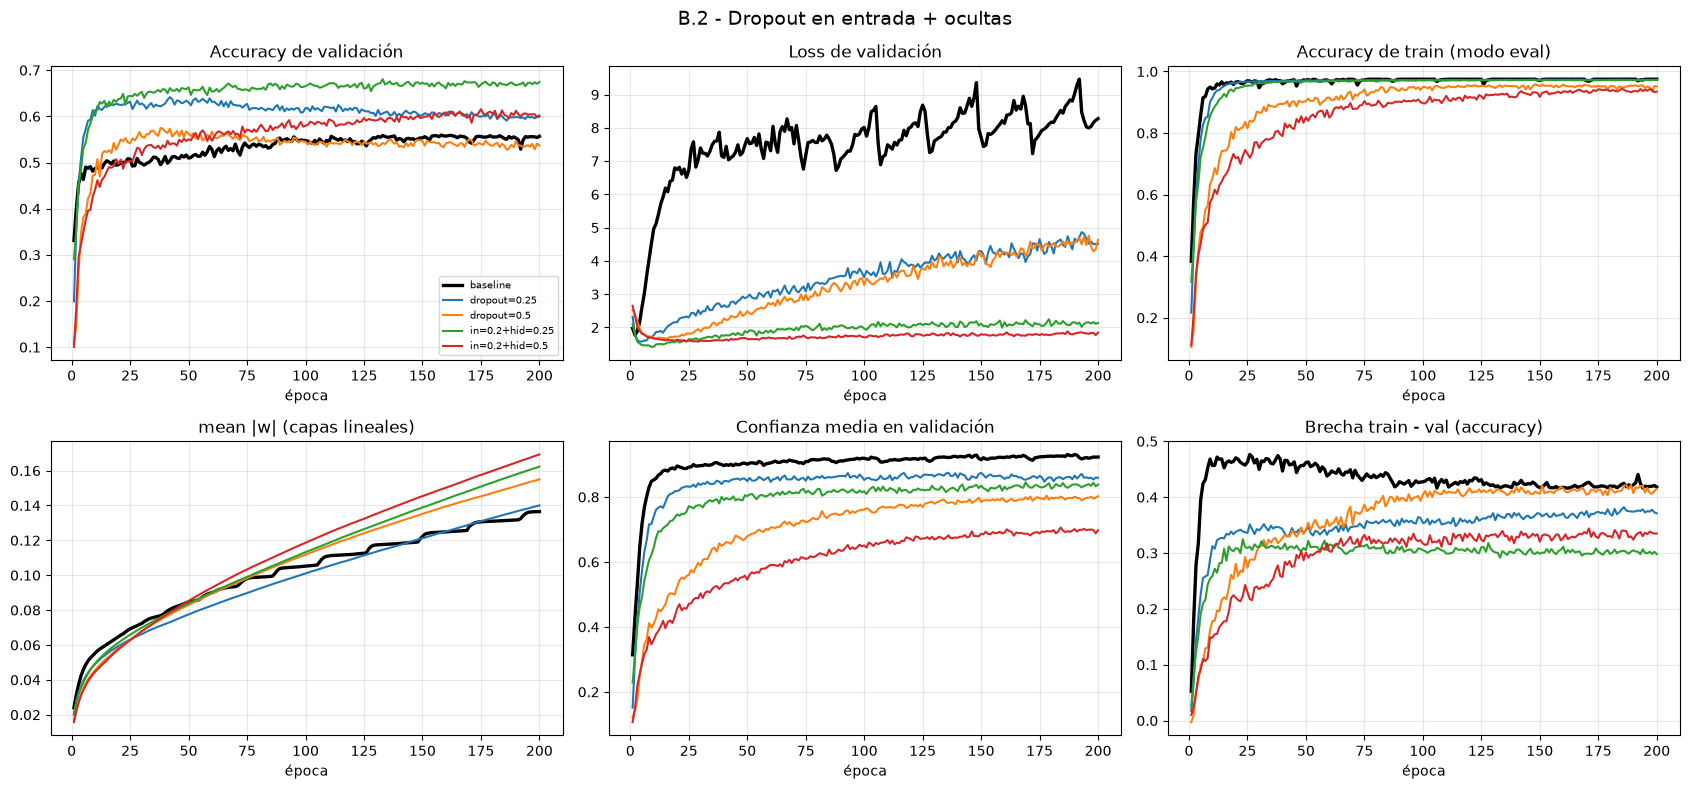

,best_val_acc,best_epoch,final_val_acc,final_val_loss,final_train_acc,brecha,confianza,mean|w|,max|w|,% |w|<1e-3,s/epoca,t total (s),t a mejor ép. (s),t a 60% (s),ruido val,ruido train(modo train)
run,,,,,,,,,,,,,,,,
baseline,0.5594,158,0.5568,8.2773,0.9749,0.4181,0.9230,0.1365,2.0494,0.6084,0.2022,40.4381,31.8631,NaN,0.0035,0.0032
dropout=0.25,0.6416,42,0.6019,4.5092,0.9729,0.3711,0.8592,0.1401,4.7362,1.5345,0.2303,46.0590,9.5970,2.0029,0.0040,0.0025
dropout=0.5,0.5749,38,0.5369,4.6314,0.9514,0.4145,0.8022,0.1550,4.4241,1.3699,0.2312,46.2441,8.9539,NaN,0.0055,0.0032
in=0.2+hid=0.25,0.6805,133,0.6743,2.1387,0.9724,0.2981,0.8385,0.1623,3.9323,0.9213,0.4101,82.0284,54.4576,3.8524,0.0040,0.0029
in=0.2+hid=0.5,0.6156,175,0.5996,1.8469,0.9347,0.3351,0.6978,0.1693,3.5947,0.9990,0.4358,87.1695,76.1965,61.1739,0.0047,0.0039


In [ ]:
for p_in, p in [(0.2, 0.25), (0.2, 0.5)]:
    n = f"in={p_in:g}+hid={p:g}"
    run_experiment(n, "Dropout", dropout=p, input_dropout=p_in, verbose=False)

in_names = [f"in=0.2+hid={p:g}" for p in (0.25, 0.5)]
plot_group(["baseline", "dropout=0.25", "dropout=0.5"] + in_names, "B.2 - Dropout en entrada + ocultas")
summarize(["baseline", "dropout=0.25", "dropout=0.5"] + in_names)

**Observaciones**:
- Aplicando dropout ambos en la entrada y en las capas ocultas, se obtiene el mejor resultado de entre los vistos hasta este punto del trabajo. Se reduce la brecha y se llega a un accuracy de 0,6805 como máximo. 
- Es mucho más estable en que con dropout solo en ocultas, la validación llegaba a su pico en la época 42 y después decaía unos 4 puntos. Con dropout en la entrada, el pico es la época 133 y la última queda a 0.6 puntos.
- La loss de validación baja un 74% respecto del baseline (de 8.28 a 2.14), y la confianza (0.84) se acerca bastante a la accuracy (0.68).
- Los tiempos de convergencía ahora sí aumentan considerablemente con respecto a baseline y a cuando se aplica droupout solo en las capas ocultas. Y se ve en el promedio de los pesos que este aumenta levemente con esta combinación, lo cual es consistente con lo que habíamos visto anteriormente.
- Con p=0.5 en la capa oculta, el resultado es mejor cuando también se aplica dropout en la entrada pero sigue sin superar al rendimiento que se obtiene teniendo solo p=0.25 en la oculta. 

## Combinación de dropout + learning rate grande con decay y momentum + max_norm + ReduceL2OnPlateau

- Se usa p=0.25 que está dentro del rango 0.2-0.5 propuesto en clase
- Se aumenta el learning rate por un factor de 10 o hasta 100 con decay y momentum de 0.9
- Se implementa **max-norm** (valores de 4 o 5)" y `ReduceLROnPlateau` cuando la métrica se estabiliza. Con max-norm: *"los pesos no superan el valor configurado, hubo que aumentar las épocas a 10k, mucho más estable (menos sensible al valor de dropout)"*.

Se usa **Adam** (que ya incorpora momentum con `β₁=0.9`), `lr × 10`, `ReduceLROnPlateau` (factor 0.5, paciencia 2 sobre la loss de validación). Comparamos todo contra el baseline y el dropout simple con las mismas épocas. Usamos max-norm `4` (valor de clase) y `1` (más restrictivo, porque con TF-IDF las normas de partida son chicas).

p elegido (mejor dropout en capas ocultas): 0.25


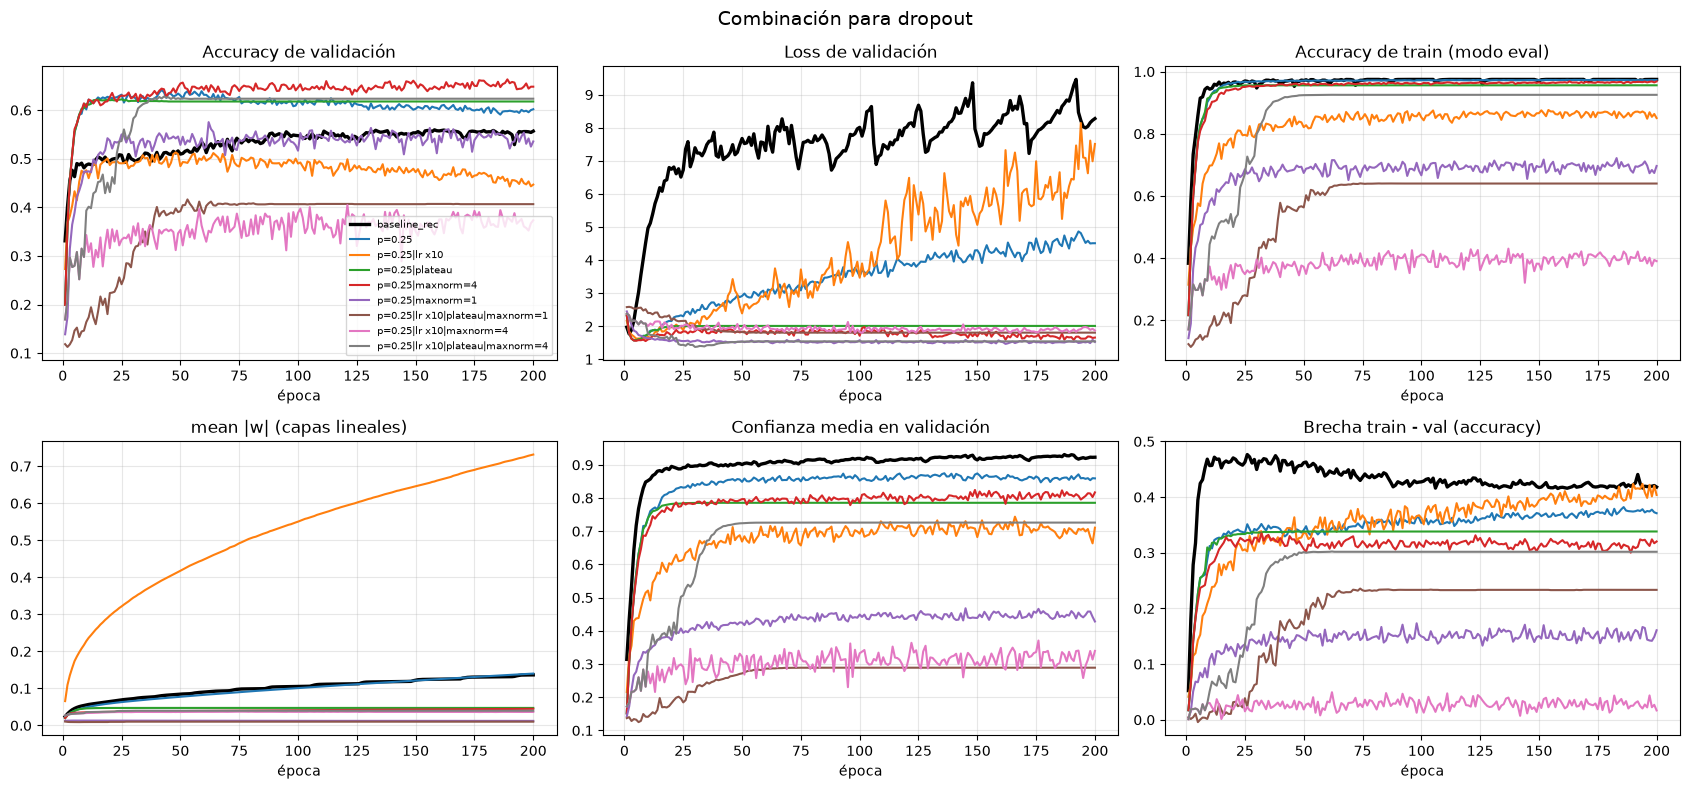

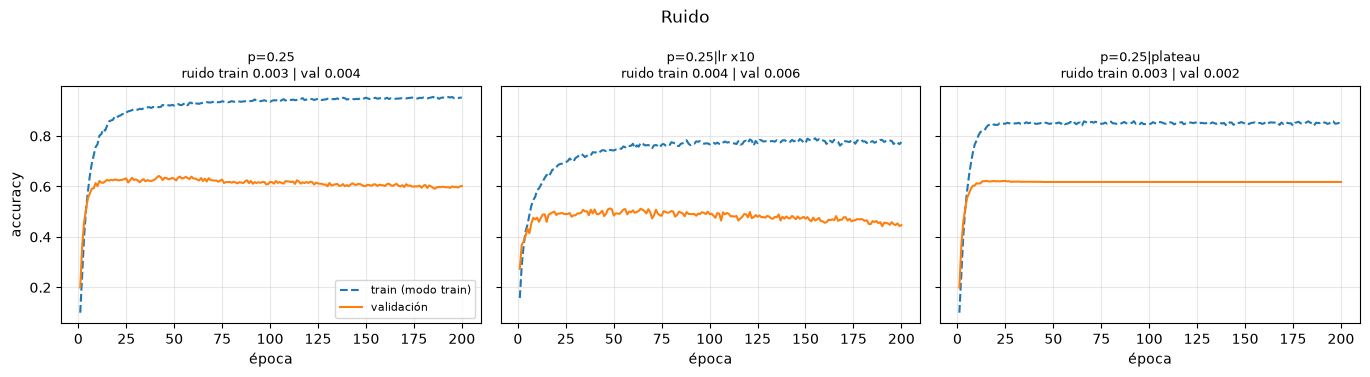

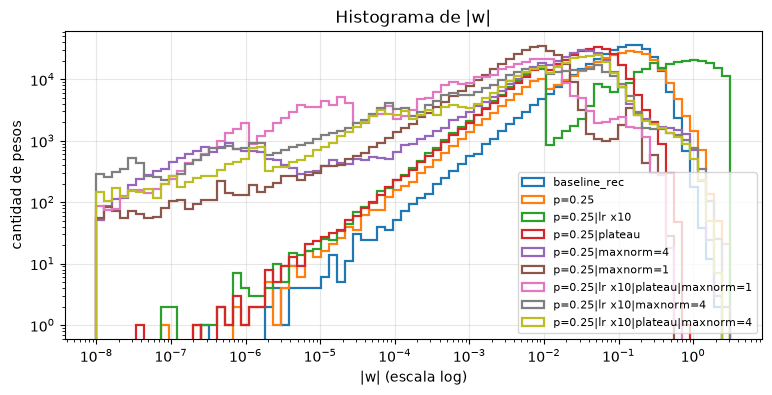

,best_val_acc,best_epoch,final_val_acc,final_val_loss,final_train_acc,brecha,confianza,mean|w|,max|w|,% |w|<1e-3,s/epoca,t total (s),t a mejor ép. (s),t a 60% (s),ruido val,ruido train(modo train)
run,,,,,,,,,,,,,,,,
baseline_rec,0.5594,158,0.5568,8.2773,0.9749,0.4181,0.9230,0.1365,2.0494,0.6084,0.2118,42.3555,33.6503,NaN,0.0035,0.0032
p=0.25,0.6416,42,0.6019,4.5092,0.9729,0.3711,0.8592,0.1401,4.7362,1.5345,0.2537,50.7408,10.4161,2.4679,0.0040,0.0025
p=0.25|lr x10,0.5130,48,0.4468,7.5099,0.8506,0.4039,0.7108,0.7316,12.3218,2.4126,0.2379,47.5753,11.2388,NaN,0.0064,0.0040
p=0.25|plateau,0.6222,15,0.6178,2.0093,0.9560,0.3383,0.7857,0.0473,0.7157,2.2803,0.2356,47.1298,3.3535,1.7847,0.0021,0.0027
p=0.25|maxnorm=4,0.6633,189,0.6483,1.6571,0.9685,0.3203,0.8170,0.0449,2.3760,8.8295,0.2792,55.8455,51.3447,2.0332,0.0045,0.0027
p=0.25|maxnorm=1,0.5753,62,0.5356,1.5260,0.6964,0.1608,0.4283,0.0123,0.4833,13.9516,0.3630,72.5955,27.0494,NaN,0.0088,0.0038
p=0.25|lr x10|plateau|maxnorm=1,0.4163,53,0.4065,1.8061,0.6399,0.2334,0.2891,0.0102,0.6666,36.3198,0.3019,60.3727,15.9533,NaN,0.0048,0.0037
p=0.25|lr x10|maxnorm=4,0.4048,121,0.3734,1.8714,0.3902,0.0168,0.3396,0.0365,2.5205,26.9197,0.2920,58.4073,35.3244,NaN,0.0164,0.0052
p=0.25|lr x10|plateau|maxnorm=4,0.6279,43,0.6235,1.5422,0.9253,0.3018,0.7261,0.0397,2.2613,18.1102,0.3107,62.1406,15.5625,11.8821,0.0071,0.0034


In [64]:
p_star = 0.25
print("p elegido (mejor dropout en capas ocultas):", p_star)

rec = []
def rrun(name, **kw):
    run_experiment(name, "DropoutRecipe", epochs=EPOCHS, verbose=False, **kw)   # mismas épocas que el resto
    rec.append(name)

rrun("baseline_rec")
rrun(f"p={p_star:g}", dropout=p_star)
rrun(f"p={p_star:g}|lr x10",       dropout=p_star, lr=BASE["lr"] * 10)
rrun(f"p={p_star:g}|plateau",      dropout=p_star, plateau=True)
rrun(f"p={p_star:g}|maxnorm=4",    dropout=p_star, max_norm=4.0)
rrun(f"p={p_star:g}|maxnorm=1",    dropout=p_star, max_norm=1.0)

rrun(f"p={p_star:g}|lr x10|plateau|maxnorm=1", dropout=p_star, lr=BASE["lr"] * 10, plateau=True, max_norm=1.0)
rrun(f"p={p_star:g}|lr x10|maxnorm=4", dropout=p_star, lr=BASE["lr"] * 10, max_norm=4.0)
rrun(f"p={p_star:g}|lr x10|plateau|maxnorm=4", dropout=p_star, lr=BASE["lr"] * 10, plateau=True, max_norm=4.0)

plot_group(rec, "Combinación para dropout")
plot_noise(rec[1:4], "Ruido")
plot_weight_hist(rec, "Histograma de |w|")
summarize(rec)

**Observaciones**:
- Un learning rate más alto reduce el tiempo de corrida total pero no el que se tarda a llegar a la mejor época dado a que debe oscilar más antes de converger. Y no reduce mejor la brecha con el lr original, sino que se obtiene un valor muy parecido al de baseline. Además, al aumentar lr, aumenta la loss de validación y el valor de los pesos. Se llega a un valor máximo de 12 y se produce más ruido tanto en val como en train. 
- Añadiendo el ReduceLROnPlateau, se logra reducir más la brecha que solo con dropout pero esto puede deberse a que también hay una reducción leve en el accuracy de train. 
Además se reducen los tiempos de convergencia y el valor de los pesos en general, dado que el lr se va reduciendo y la red deja de crecer, quedando los pesos chicos. 
Sí se logra bajar más la loss en validación en comparación a con solo dropout. 
- Entre max_norm= 1 y max_norm=4, se obtuvieron mejores resultados con esta última. 
Con max_norm=1 la accuracy de train cae a 0.696, lo que indica underfitting. El límite es demasiado estricto para una capa de entrada de 10.000 pesos por neurona. Los pesos quedan acotados y bajos (promedio 0.0123 y máximo 0.4833, contra 0.0449 y 2.376 con max_norm=4). Además, el modelo queda subconfiado (confianza 0.43 contra accuracy 0.54), lo que explica su loss de validación baja a pesar de clasificar peor. Con respecto a los tiempos, max_norm=1 alcanza su mejor época antes, pero esto se debe a que se estanca y después empeora. Mientras que con max_norm=4 sigue mejorando hasta casi el final y mantiene la accuracy estable (0.6483 en la última época).
- Combinar las tres modificaciones no mejoró los resultados de max_norm=4 solo. 
Con learning rate x10 sin plateau, max_norm=4 no logra aprender (accuracy de train 0.39) y la curva de validación es la más ruidosa (0.0164).
Agregando ReduceLROnPlateau el modelo mejora y muestra la menor loss en validación, pero no supera a max_norm=4 solo. 
Con max_norm=1 el modelo subajusta incluso con plateau (0.416).


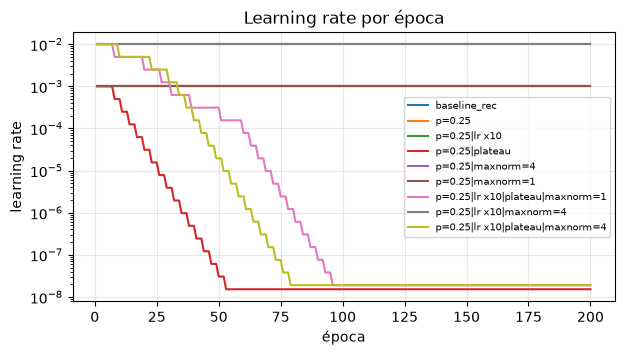

In [65]:
# Evolución del learning rate con ReduceLROnPlateau
plt.figure(figsize=(7, 3.5))
for n in rec:
    plt.plot(range(1, EPOCHS + 1), RESULTS[n]["hist"]["lr"], label=n)
plt.yscale("log"); plt.xlabel("época"); plt.ylabel("learning rate"); plt.grid(alpha=.3)
plt.legend(fontsize=7); plt.title("Learning rate por época"); plt.show()

El gráfico de learning rate por época muestra que ReduceLROnPlateau reduce el lr a medida que avanzan las épocas. Desde ese punto los pesos prácticamente no se actualizan, por lo que el modelo queda en el estado alcanzado y el accuracy de validación final coincide casi con el máximo. Termina cumpliendo la función de un early stopping en que la estabilidad de la curva se debe a que el entrenamiento se detiene y no a que el modelo generalice mejor. Con lr constante (1e-3 o 1e-2) la red sigue actualizándose durante las 200 épocas y en el gráfico se ven como rectas. 

# Batch Normalization

Batch Normalization **acelera el entrenamiento** y brinda una **regularización leve**. como la media y la varianza se calculan por mini-batch. El efecto es parecido al de dropout pero en este caso en vez de sacar algunas de las salidas, se da por el ruido generado. 
No es estrictamente no es una técnica de regularización sino de aceleración del entrenamiento. 

Se hace un barrido de `lr ∈ {1e-4, 1e-3, 1e-2, 1e-1}` con y sin BN. La hipótesis es que BN tolera learning rates más altos.

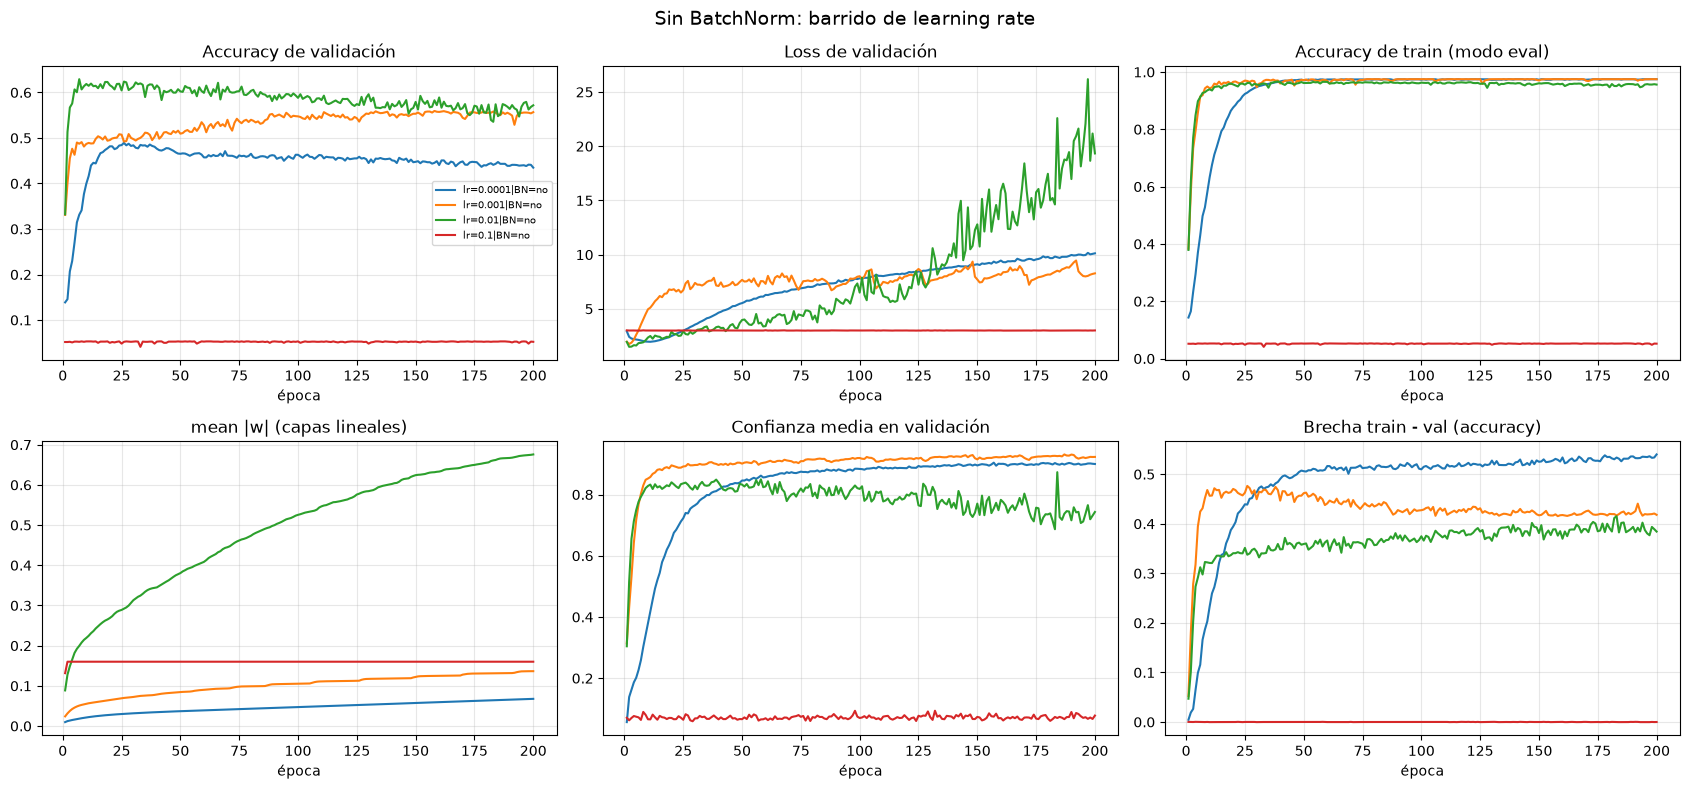

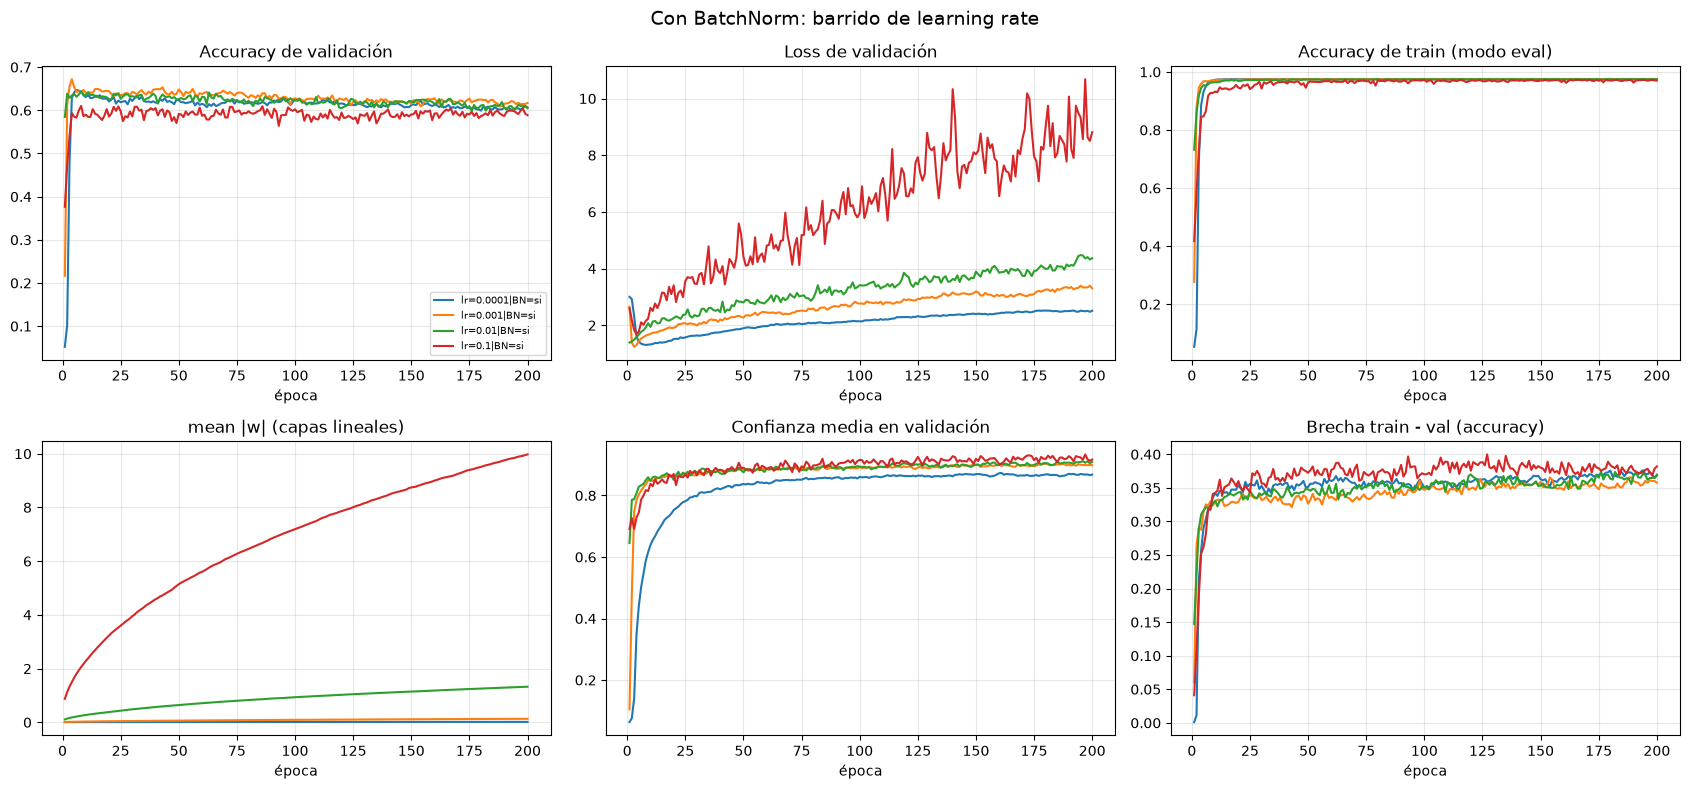

,best_val_acc,best_epoch,final_val_acc,final_val_loss,final_train_acc,brecha,confianza,mean|w|,max|w|,% |w|<1e-3,s/epoca,t total (s),t a mejor ép. (s),t a 60% (s),ruido val,ruido train(modo train)
run,,,,,,,,,,,,,,,,
lr=0.0001|BN=no,0.4892,26,0.4348,10.1254,0.9748,0.5400,0.8998,0.0676,0.8908,1.1116,0.2166,43.3261,5.6005,NaN,0.0029,0.0008
lr=0.0001|BN=si,0.6469,6,0.6067,2.5110,0.9748,0.3681,0.8678,0.0179,0.5467,4.3480,0.3593,71.8665,2.2831,1.5752,0.0103,0.0035
lr=0.001|BN=no,0.5594,158,0.5568,8.2773,0.9749,0.4181,0.9230,0.1365,2.0494,0.6084,0.2151,43.0241,34.0665,NaN,0.0035,0.0032
lr=0.001|BN=si,0.6721,4,0.6169,3.3028,0.9746,0.3577,0.8984,0.1324,1.3435,0.4966,0.3556,71.1140,1.3204,0.6615,0.0089,0.0048
lr=0.01|BN=no,0.6293,7,0.5718,19.3356,0.9561,0.3843,0.7431,0.6758,13.2900,1.6679,0.2381,47.6103,2.0206,1.2771,0.0075,0.0039
lr=0.01|BN=si,0.6438,8,0.6049,4.3656,0.9747,0.3697,0.9092,1.3268,20.6747,0.0534,0.3722,74.4442,2.8549,0.6924,0.0042,0.0044
lr=0.1|BN=no,0.0530,8,0.0521,3.0141,0.0521,0.0000,0.0781,0.1601,6.1628,7.5396,0.2580,51.5913,2.0343,NaN,0.0010,0.0019
lr=0.1|BN=si,0.6103,8,0.5886,8.8123,0.9705,0.3819,0.9169,9.9733,187.2256,0.6469,0.3609,72.1752,2.7025,2.7025,0.0064,0.0038


In [69]:
bn_lr = []
for lr in [1e-4, 1e-3, 1e-2, 1e-1]:
    for bn in [False, True]:
        n = f"lr={lr:g}|BN={'si' if bn else 'no'}"
        run_experiment(n, "BN_LR", lr=lr, batchnorm=bn, verbose=False)
        bn_lr.append(n)

plot_group([n for n in bn_lr if "BN=no" in n], "Sin BatchNorm: barrido de learning rate")
plot_group([n for n in bn_lr if "BN=si" in n], "Con BatchNorm: barrido de learning rate")
summarize(bn_lr)

- Al agregar BatchNorm, el accuracy de validación pasa de 0.489 a 0.647 con lr=1e-4 y de 0.559 a 0.672 con lr=1e-3. Con lr=1e-2 la diferencia no es considerable (0.629 vs 0.644) y con lr=0.1 la red sin BN colapsa mientras que con BN alcanza 0.610. 
- Con BN el pico de validación se alcanza en 4 a 8 épocas (1.3 s con lr=1e-3), mientras que sin BN a 158 épocas (32 s). Se comprueba que es una técnica que acelera el entrenamiento. 
- Se observa que el overfitting no se reduce porque el accuracy de entrenamiento llega a aprox. 0.97 en todos los casos y en la validación cae.
Por lo que la menor brecha a lr bajo se debe al mejor accuracy de validación y no a un efecto regularizador. 
- Con BN la loss de validación final es menor y la confianza se reduce a lr bajo. 
- Los valores absolutos de los pesos crecen con el lr sin empeorar el rendimiento, lo que es esperable porque con BN la salida es invariante a la escala de los pesos de cada neurona.

## Tamaño de batch

Con batches chicos la estimación es más ruidosa; con batches grandes se parece más a la estadística global. Se barre `bs ∈ {32, 64, 128, 256}` con y sin BN, con `lr=1e-3` fijo.

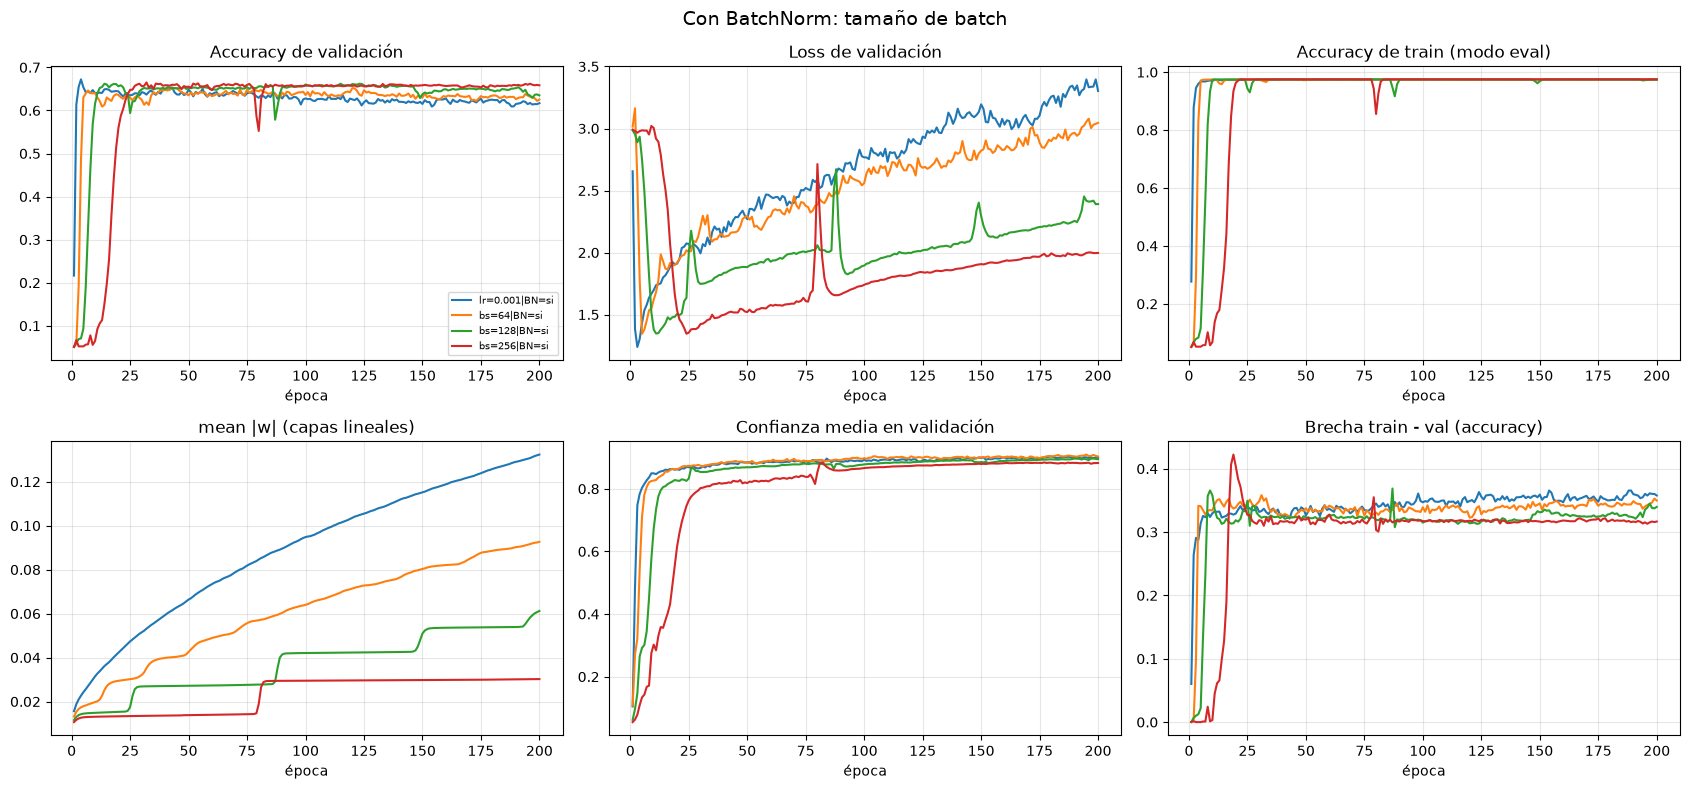

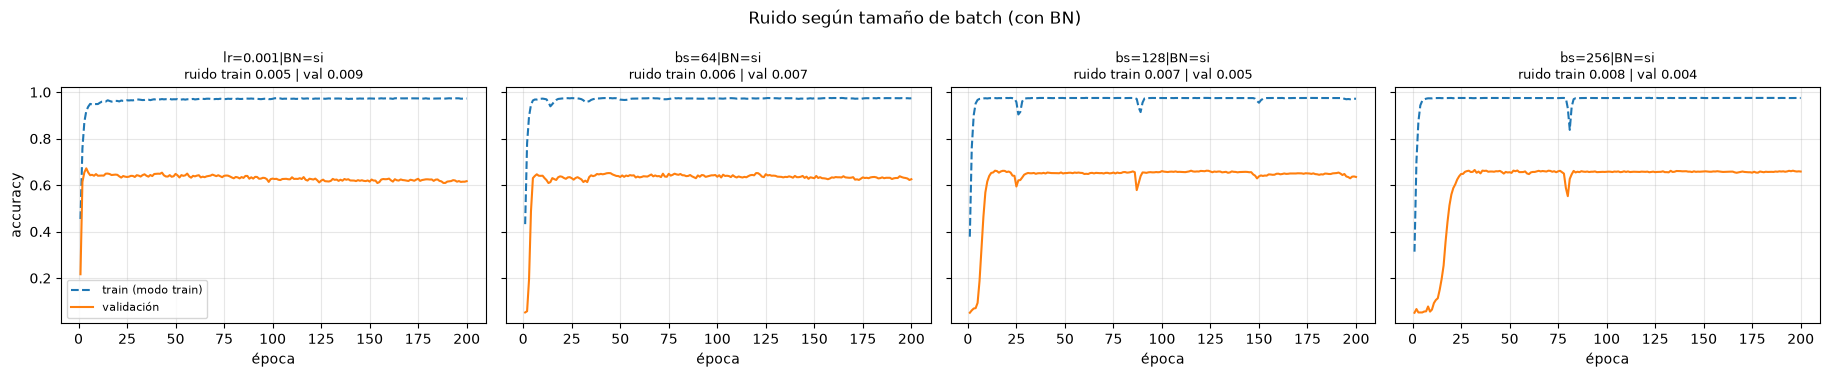

,best_val_acc,best_epoch,final_val_acc,final_val_loss,final_train_acc,brecha,confianza,mean|w|,max|w|,% |w|<1e-3,s/epoca,t total (s),t a mejor ép. (s),t a 60% (s),ruido val,ruido train(modo train)
run,,,,,,,,,,,,,,,,
lr=0.001|BN=no,0.5594,158,0.5568,8.2773,0.9749,0.4181,0.9230,0.1365,2.0494,0.6084,0.2151,43.0241,34.0665,NaN,0.0035,0.0032
lr=0.001|BN=si,0.6721,4,0.6169,3.3028,0.9746,0.3577,0.8984,0.1324,1.3435,0.4966,0.3556,71.1140,1.3204,0.6615,0.0089,0.0048
bs=64|BN=no,0.5599,195,0.5577,7.9350,0.9750,0.4174,0.9243,0.1022,1.7857,0.9693,0.1356,27.1297,26.4748,NaN,0.0054,0.0040
bs=64|BN=si,0.6518,44,0.6253,3.0452,0.9750,0.3498,0.9032,0.0926,1.1217,0.7024,0.2131,42.6120,8.6707,0.9847,0.0074,0.0058
bs=128|BN=no,0.5312,194,0.5285,6.6798,0.9749,0.4464,0.9156,0.0849,1.3436,0.8444,0.1061,21.2226,20.5776,NaN,0.0042,0.0029
bs=128|BN=si,0.6620,14,0.6350,2.3909,0.9747,0.3397,0.8945,0.0612,0.6892,1.0324,0.1435,28.6932,1.9628,1.3992,0.0048,0.0068
bs=256|BN=no,0.4609,7,0.4459,9.5177,0.9749,0.5291,0.9065,0.0740,1.2654,0.9407,0.0873,17.4542,0.6056,NaN,0.0031,0.0042
bs=256|BN=si,0.6650,32,0.6584,1.9971,0.9750,0.3166,0.8825,0.0302,0.5121,2.2992,0.1083,21.6548,3.4783,2.3597,0.0043,0.0077


In [70]:
bn_bs = ["lr=0.001|BN=no", "lr=0.001|BN=si"]  # son los de bs=32 (ya corridos en C.1)
for bs in [64, 128, 256]:
    for bn in [False, True]:
        n = f"bs={bs}|BN={'si' if bn else 'no'}"
        run_experiment(n, "BN_BS", batch_size=bs, batchnorm=bn, verbose=False)
        bn_bs.append(n)

plot_group([n for n in bn_bs if "BN=si" in n], "Con BatchNorm: tamaño de batch")
plot_noise([n for n in bn_bs if "BN=si" in n], "Ruido según tamaño de batch (con BN)")
summarize(bn_bs)

**Observaciones**:
- Con lr=1e-3 fijo y sin BN, el  accuracy de validación cae al aumentar el batch (0.559 con 32 y 64, 0.531 con 128 y 0.461 con 256), que es tiene sentido con la menor cantidad de ruido en el gradiente de los batches grandes. 
- Con BN, el mejor accuracy se mantiene entre 0.652 y 0.672 para todos los tamaños. Entonces, se ve que el modelo es poco sensible al batch con los valores que utilizamos. El rendimiento mejora con el aumento del tamaño del batch (0.617 con 32 y 0.658 con 256) con una menor loss de validación (3.30 a 2.00) y menor ruido en la curva de validación (0.0089 a 0.0043). 
- En tiempos, el costo por época disminuye con el batch (de 0.356 a 0.108 s con BN), pero el tiempo hasta el 60% de accuracy aumenta (0.66 s con 32 y 2.36 s con 256), porque con lr fijo el progreso depende del número de pasos.

## Momentum de BN

Se usa un **promedio móvil exponencial** de los mini-batches de entrenamiento: `running = m·running + (1-m)·batch`. 
Probamos `m ∈ {0.9, 0.99, 0.999}` (en PyTorch `momentum = 1 - m`).

Un `m` muy alto hace que las estadísticas de `eval()` reaccionen lento a los cambios de la red; uno muy bajo las vuelve ruidosas.

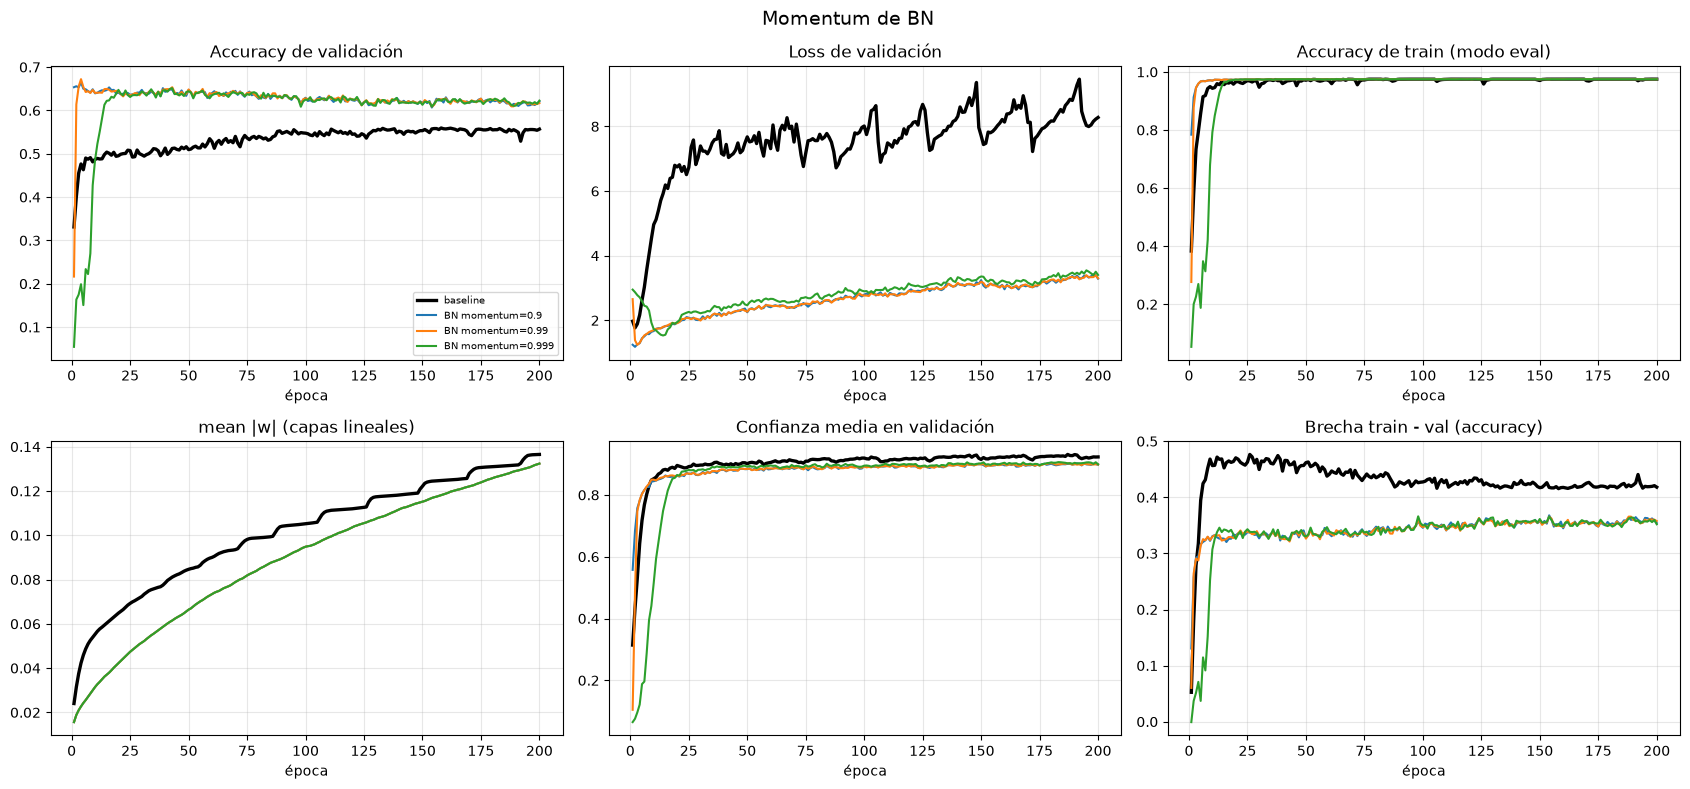

,best_val_acc,best_epoch,final_val_acc,final_val_loss,final_train_acc,brecha,confianza,mean|w|,max|w|,% |w|<1e-3,s/epoca,t total (s),t a mejor ép. (s),t a 60% (s),ruido val,ruido train(modo train)
run,,,,,,,,,,,,,,,,
baseline,0.5594,158,0.5568,8.2773,0.9749,0.4181,0.9230,0.1365,2.0494,0.6084,0.2022,40.4381,31.8631,NaN,0.0035,0.0032
BN momentum=0.9,0.6646,4,0.6204,3.2898,0.9746,0.3542,0.8978,0.1324,1.3435,0.4966,0.3486,69.7210,1.3657,0.3576,0.0032,0.0048
BN momentum=0.99,0.6721,4,0.6169,3.3028,0.9746,0.3577,0.8984,0.1324,1.3435,0.4966,0.3222,64.4368,1.3595,0.6968,0.0089,0.0048
BN momentum=0.999,0.6513,43,0.6226,3.4052,0.9746,0.3520,0.8994,0.1324,1.3435,0.4966,0.3167,63.3304,13.6702,4.4314,0.0069,0.0048


In [73]:
bn_mom = []
for m in [0.9, 0.99, 0.999]:
    n = f"BN momentum={m:g}"
    run_experiment(n, "BN_MOM", batchnorm=True, bn_momentum=m, verbose=False)
    bn_mom.append(n)

plot_group(["baseline"] + bn_mom, " Momentum de BN")
summarize(["baseline"] + bn_mom)

**Observaciones**:
- El acurracy de validación y los pesos son practicamente iguales con cualquiera de los valores de momentum. 
- Con 0.9 el 60% se alcanza en 0.36 s, con 0.99 en 0.70 s y con 0.999 en 4.4 s, con el máximo desplazado a la época 43. Esto se debe a que con momentum alto las estadísticas móviles tardan en reflejar el estado del modelo, por lo que las métricas de validación subestiman al modelo durante las primeras épocas. Este desfase se produce por la validación y no el entrenamiento. 


# Comparación final en test

Para cada técnica se elige la **mejor configuración según la validación** (accuracy en la última época) y se reentrena con **todo** el train original. Se evalúa contra el **test set** y se reporta la **última época**.

Se compara: línea base, mejor regularización L1/L2, mejor dropout y mejor BN.

In [74]:
X_full, X_test = build_features(train_proc, test_proc)
DATA_FULL = {}
DATA_FULL["X_tr"], DATA_FULL["y_tr"] = to_tensors(X_full, newsgroups_train.target)
DATA_FULL["X_ev"], DATA_FULL["y_ev"] = to_tensors(X_test, newsgroups_test.target)

PICKS = {
    "Baseline": "baseline",
    "Regularización (L1/L2)": best_in(["L2", "L1", "L1+L2"]),
    "Dropout": best_in(["Dropout"]),
    "BatchNorm": best_in(["BN_LR", "BN_BS", "BN_MOM"], cond=lambda c: c["batchnorm"]),
}
for k, v in PICKS.items():
    print(f"{k:24s} -> {v}")

FINAL = {}
for tech, src in PICKS.items():
    cfg = {k: v for k, v in RESULTS[src]["cfg"].items()}
    FINAL[tech] = f"final | {tech}"
    run_experiment(FINAL[tech], "final", data=DATA_FULL, verbose=False, **cfg)

Baseline                 -> baseline
Regularización (L1/L2)   -> L1=1e-06
Dropout                  -> in=0.2+hid=0.25
BatchNorm                -> bs=256|BN=si


,config elegida,test_acc,macro_F1,brecha train-test,confianza,mean|w|,% |w|<1e-3,s/epoca,ruido (curva test)
técnica,,,,,,,,,
Baseline,baseline,0.5141,0.5090,0.4599,0.9258,0.1369,0.5878,0.2653,0.0059
Regularización (L1/L2),L1=1e-06,0.5194,0.5129,0.4545,0.8982,0.0356,63.9836,0.3316,0.0036
Dropout,in=0.2+hid=0.25,0.6182,0.6039,0.3507,0.8044,0.1811,1.0841,0.5005,0.0030
BatchNorm,bs=256|BN=si,0.5947,0.5888,0.3794,0.8696,0.0455,1.4268,0.1623,0.0041


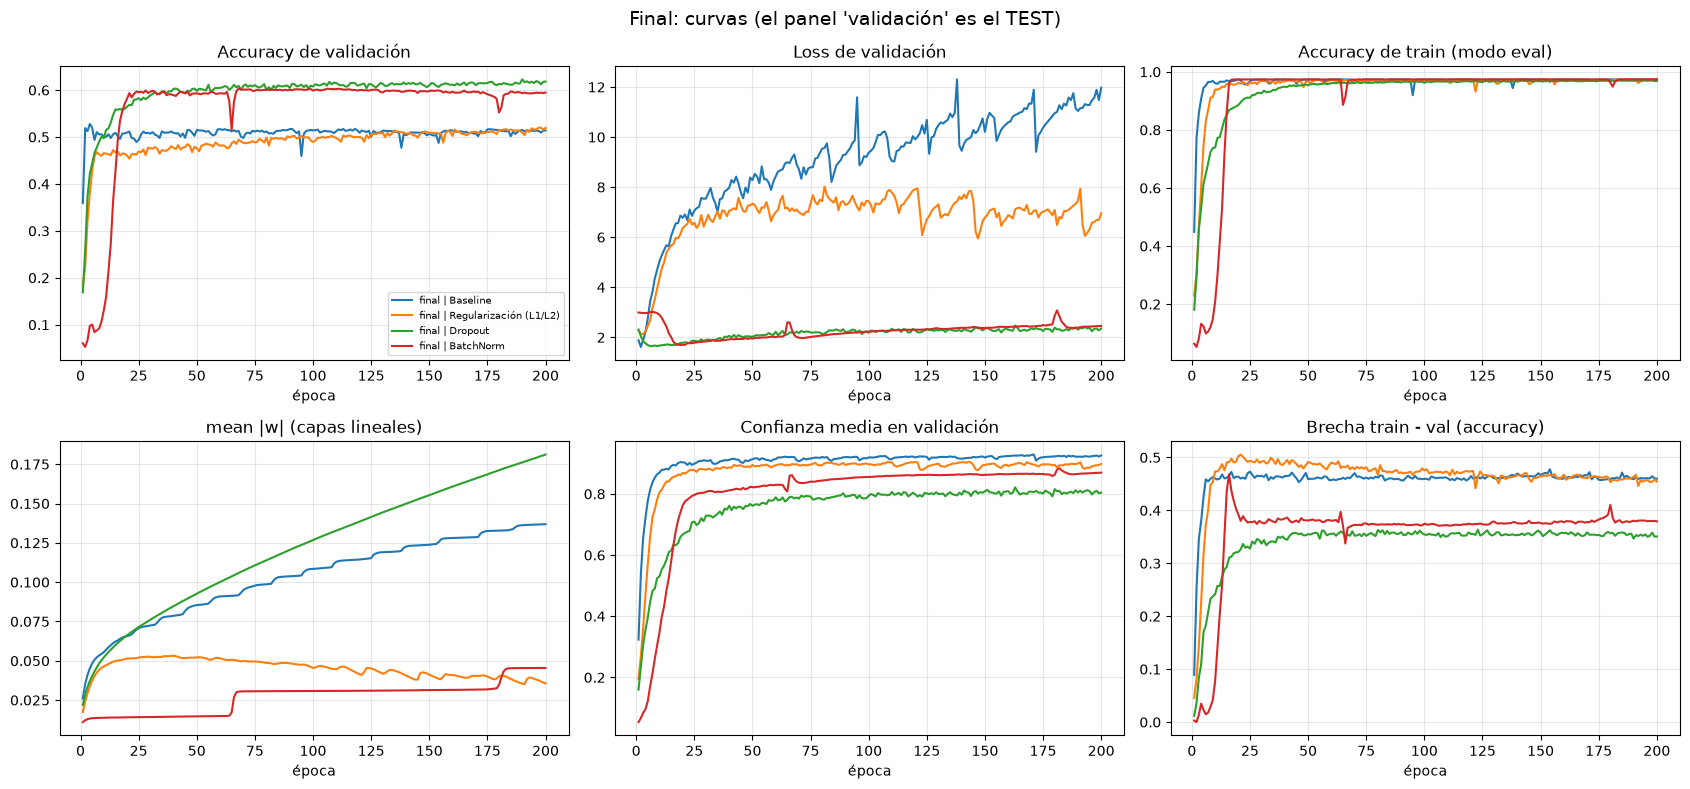

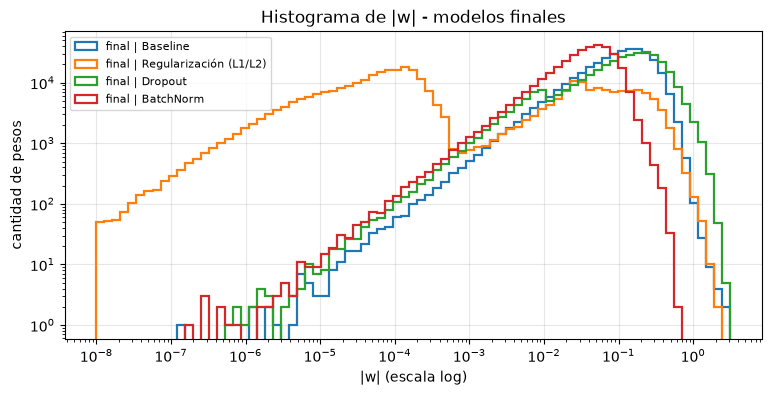

In [75]:
@torch.no_grad()
def predict(model, X):
    model.eval()
    return torch.cat([model(X[i:i + 1024].to(device)).argmax(1).cpu() for i in range(0, len(X), 1024)]).numpy()

y_test = DATA_FULL["y_ev"].numpy()
rows = []
for tech, n in FINAL.items():
    y_hat = predict(RESULTS[n]["model"], DATA_FULL["X_ev"])
    s = summarize([n]).iloc[0]
    rows.append({"técnica": tech, "config elegida": PICKS[tech],
                 "test_acc": round(float((y_hat == y_test).mean()), 4),
                 "macro_F1": round(float(f1_score(y_test, y_hat, average="macro")), 4),
                 "brecha train-test": round(float(s["brecha"]), 4), "confianza": s["confianza"],
                 "mean|w|": s["mean|w|"], "% |w|<1e-3": s["% |w|<1e-3"], "s/epoca": s["s/epoca"],
                 "ruido (curva test)": s["ruido val"]})
df_final = pd.DataFrame(rows).set_index("técnica")
display(df_final)

plot_group(list(FINAL.values()), "Final: curvas (el panel 'validación' es el TEST)")
plot_weight_hist(list(FINAL.values()), "Histograma de |w| - modelos finales")

**Referencia:** softmax lineal `0.6581` en test (train `0.9723`).

**Observaciones finales**:
- Dropout (entrada 0.2 y capas ocultas 0.25) obtuvo la mayor accuracy (0.618, macro-F1 0.604), seguido por BatchNorm con batch 256 (0.595) y, más por debajo, la regularización L1 con λ=1e-6 (0.519), que no se distingue del baseline (0.514). 
- Las mejoras de dropout y BN son mucho mayores, pero se tendría que probar variar la semilla. 
- El accuracy de train es prácticamente igual en todas las técnicas (≈0.97), por lo que la reducción de la brecha train-test (de 0.46 a 0.35 con dropout) se debe a un mayor rendimiento en test y no a un menor ajuste del train. 
- El dropout además reduce a la mitad la confianza del modelo, mientras que L1 produce un modelo muy esparso (64% de pesos menores a 1e-3 y un valor absoluto medio cuatro veces menor) sin mejorar la generalización. 
- En costo por época, el dropout casi lo duplica, L1 lo aumenta 25% y BN con batch 256 lo reduce por el menor número de pasos. 
- Ninguna variante supera al modelo lineal softmax (0.658 en test), lo que sugiere que, para este dataset, la regularización ayuda pero no elimina el overfitting del MLP.

# 5. Conclusiones


**Regularización L1/L2.** Ambas penalizan la magnitud de los pesos y con λ demasiado grande, la penalidad domina y la red presenta underfitting. Ninguno de los dos mejoró el rendimiento pero con los mismos λ, L1 resultó afectar más los pesos que L2 porque los estos son pequeños (~0.01) y su gradiente constante los lleva a cero. Mientras que el de L2 se hace más chico a medida que el peso se achica. 

L1 produjo pesos más concentrados alrededor de 0 (por ejemplo, con λ=1e-6 el 64% de los pesos queda por debajo de 1e-3 y el valor absoluto medio baja unas cuatro veces), con los pesos sobrevivientes más grandes. También se comprobó que las redes regularizadas se pueden podar más sin perder accuracy. 
Aún así, la esparsidad no mejoró la generalización porque el test L1 no se distingue del baseline (0.519 contra 0.514) y L2 con Adam tampoco mejoró la accuracy. 


**Dropout y max-norm.** Dropout fue la técnica que más mejoró el rendimiento (valores de p entre 0.1 y 0.3, y el mejor resultado global con dropout también en la entrada), pero duplicando el tiempo por época. También se observó que reduce a la mitad la confianza del modelo. 

Max-norm=4 fue la mejor variante entre las que se probaron, mientras que max-norm=1 mostró underfitting. Subir el lr como se vio en clase no funcionó con Adam, y se pudo observar que ReduceLROnPlateau funciona como un early stopping que al bajar el lr a ~1e-8 y hacía que el modelo deje de moverse porque el lr era casi cero.


**BatchNorm.** Permite usar learning rates mucho más altos (con lr=0.1 la red sin BN colapsa al azar y con BN alcanza 0.61) y converge en muy pocas épocas (pico en 4-8 épocas, 1.3 s, contra 158 épocas, 32 s, sin BN), aunque cada época cuesta mucho más. No ayuda a salir del overfitting como era de esperarse porque no es una técnica de regularización sino que de aceleración del entrenamiento. 

Con BN la magnitud de los pesos pierde significado porque la salida es invariante a su escala. Además, se vio que el momentum de BN no cambia el entrenamiento sino solo las estadísticas usadas en `eval()`. Puede ser que el ruido de validación baje con el tamaño del batch pero este resultado estaba mezclado con la cantidad de pasos y no se le pudo atribuir completamente. 



## Visualización en TensorBoard

In [85]:
%reload_ext tensorboard
%tensorboard --logdir runs/reg

Reusing TensorBoard on port 6006 (pid 2320), started 0:01:05 ago. (Use '!kill 2320' to kill it.)